# Cosmos Reason 2 for First-Timers: The Settings That Change the Answer

*A hands-on how-to for images and video, from your first call to a tuned setup*

**By Obinna Edeh**, Head of Physical AI Lab, EmbodiedEdge

**Why I built this.** I use Cosmos Reason 2 in my own projects, including [Urban Edge Vision Analytics](https://github.com/obiedeh/urban-edge-vision-analytics), which watches live street cameras, and [Physical AI Safety Observability](https://github.com/obiedeh/physical-ai-safety-observability), a safety layer for robot workcells. In the safety project, one change to the request took false protective-gear alarms from 11 to zero on my labeled test frames. Settings like that are easy to miss, so I wrote the guide I would hand a developer new to the model: every setting measured for what it does to accuracy and response time.

**Why Google Colab.** I built it for Colab on purpose, to make the model easier to learn and adopt. It runs in a browser with nothing to install on your own machine, so a first-timer can go from zero to a working call without owning a GPU.

This notebook takes you from an empty Google Colab session to working image and video calls on **NVIDIA Cosmos Reason 2 (2B)**, then measures how each main parameter changes accuracy, reasoning and response time. Every claim about a parameter is backed by a test with a known answer that you run yourself.

**What Cosmos Reason 2 is.** A vision language model (VLM) for physical AI. You give it an image or a video plus a text question, and it answers in text. It can caption, answer questions, locate objects with bounding boxes, timestamp events in video, plan a robot's next move, and reason step by step before answering. The 2B model is built on the Qwen3-VL-2B architecture and loads through the Hugging Face `transformers` library.

**What you will do**

| Part | Topic |
|---|---|
| 1 | Set up Colab, get model access, install, load the model, build the helpers |
| 2 | First image call and first video call |
| 3 | What is inside a call: messages, the prompt, tokens |
| 4 | `max_new_tokens`: output length and time |
| 5 | Vision token budget: image detail, accuracy and time. Cropping. |
| 6 | Video: `fps`, the shared frame budget, splitting a long video |
| 7 | Context window: counting what you send |
| 8 | Where the time goes: the first token against the rest |
| 9 | Reasoning mode: accuracy against time |
| 10 | Sampling: `temperature`, `top_p`, `top_k`, `repetition_penalty`, `seed` |
| 11 | Prompt structure: media order and the system prompt, tested |
| 12 | Knowing when it is wrong: leading questions and answer agreement |
| 13 | Real footage check: a warehouse camera |
| 14 | Task gallery: NVIDIA's prompts on NVIDIA's footage |
| 15 | Several images, and follow-up questions |
| 16 | Speed and memory: batching and 4-bit loading |
| 17 | Streaming, and the same parameters on a vLLM server |
| 18 | Tune it on your own data |
| 19 | Cheat sheet and troubleshooting |

Parts 1 to 3 are the base. After Part 1 every part runs independently, so you can jump straight to the one you need. A full run makes a few hundred short calls.

**Before you start**

1. In Colab choose **Runtime > Change runtime type > T4 GPU** (or any GPU).
2. Create a free [Hugging Face](https://huggingface.co) account, open the [model page](https://huggingface.co/nvidia/Cosmos-Reason2-2B) and accept the NVIDIA Open Model License. The model is gated, so the download fails until you do.
3. Create a read token at [huggingface.co/settings/tokens](https://huggingface.co/settings/tokens). In Colab, click the key icon in the left bar, add a secret named `HF_TOKEN` and switch on notebook access.

NVIDIA lists 24 GB as the minimum GPU memory for the 2B model. That figure covers the full default vision budget. This notebook caps the vision tokens per call, which keeps memory far lower. Every result table prints the peak GPU memory so you can see it on your own runtime.

NVIDIA has since released Cosmos 3 and now maintains the Reason 2 repository in limited form. Reason 2 (2B) is still a good small model to learn on, and the parameters here carry over to other Qwen-style VLMs.

## Part 1. Setup

### 1.1 Check the GPU

In [1]:
import torch
assert torch.cuda.is_available(), "No GPU found. In Colab: Runtime > Change runtime type > T4 GPU."
gpu = torch.cuda.get_device_properties(0)
print(f"GPU: {gpu.name}, {gpu.total_memory / 1e9:.0f} GB   torch {torch.__version__}")

GPU: NVIDIA GeForce RTX 5090, 34 GB   torch 2.11.0+cu128


### 1.2 Install

Colab already has PyTorch, OpenCV, Pillow, pandas and matplotlib. The main install is `transformers`, pinned to the release NVIDIA's own sample script uses (4.57.3). Newer releases changed how video prompts are built, so the pin keeps your results in line with NVIDIA's tested setup. `bitsandbytes` is only needed for the 4-bit experiment in Part 16.

In [2]:
%pip install -q "transformers==4.57.3" accelerate bitsandbytes

Note: you may need to restart the kernel to use updated packages.


### 1.3 Log in to Hugging Face

This reads the `HF_TOKEN` secret you added. If the secret is missing it opens a login box.

In [3]:
import os
MODEL_ID = os.environ.get("COSMOS_MODEL", "nvidia/Cosmos-Reason2-2B")   # set COSMOS_MODEL to a local folder to skip the download

if not os.path.isdir(MODEL_ID):
    from huggingface_hub import login
    try:
        from google.colab import userdata
        login(token=userdata.get("HF_TOKEN"))
    except Exception:
        login()

### 1.4 Load the model and the processor

Two objects do all the work:

- the **processor** turns your text, images and video frames into numbers (tokens and pixel tensors),
- the **model** reads those numbers and generates the answer, one token at a time.

The load arguments:

| Argument | Meaning |
|---|---|
| `dtype=torch.float16` | Store weights as 16-bit floats. Half the memory of 32-bit. NVIDIA's sample uses float16; its model card reports testing in BF16, which older GPUs such as the T4 do not run natively. |
| `device_map="auto"` | Put the model on the GPU. |
| `attn_implementation="sdpa"` | Use PyTorch's built-in fast attention. Nothing extra to install. |

The first run downloads about 4.9 GB.

In [4]:
import time, warnings
import transformers
warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()

t0 = time.perf_counter()
model = transformers.Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID, dtype=torch.float16, device_map="auto", attn_implementation="sdpa"
)
processor = transformers.AutoProcessor.from_pretrained(MODEL_ID)
model.eval()
print(f"Loaded in {time.perf_counter() - t0:.0f} s")
print(f"GPU memory held by the weights: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

Loaded in 1 s
GPU memory held by the weights: 4.3 GB


### 1.5 Get the sample media

Two files from NVIDIA's `cosmos-reason2` repository (a still of a two-handed robot at a table, and a short dashcam clip), plus the real footage NVIDIA uses in its Cosmos Cookbook prompt guide: a packing robot, a drive into a construction zone, a generated block-stacking clip, a warehouse camera, a doorstep camera and a forklift photo. About 50 MB in total, fetched from NVIDIA's sites at run time.

Robot image size: (1910, 1190)


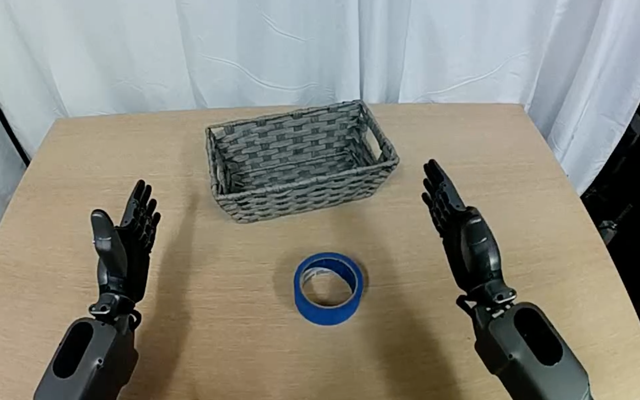

In [5]:
import urllib.request
import cv2, numpy as np
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Video

REPO = "https://raw.githubusercontent.com/nvidia-cosmos/cosmos-reason2/main/assets/"
GUIDE = "https://nvidia-cosmos.github.io/cosmos-cookbook/getting_started/prompt_guide/assets/"

def fetch(name, base):
    if not os.path.exists(name):
        try:
            urllib.request.urlretrieve(base + name, name)
        except Exception as e:
            print(f"Could not download {name}: {e}. Parts that use it will fail; the others still run.")
    return name

ROBOT_IMAGE     = fetch("sample.png", REPO)
DASHCAM_VIDEO   = fetch("sample.mp4", REPO)          # 2.5 s dashcam clip
PACKING_VIDEO   = fetch("agibot.mp4", GUIDE)         # 6.5 s, two robot arms packing a box
DRIVING_VIDEO   = fetch("ego_v.mp4", GUIDE)          # 15 s, driving into a construction zone
GENERATED_VIDEO = fetch("sdg.mp4", GUIDE)            # 6 s, AI-generated block stacking
WAREHOUSE_VIDEO = fetch("warehouse_1.mp4", GUIDE)    # 46 s, warehouse aisle camera
DOORSTEP_VIDEO  = fetch("package.mp4", GUIDE)        # 12 s, doorstep camera
FORKLIFT_IMAGE  = fetch("load.png", GUIDE)

def frame_strip(path, n=4, height=150):
    # n evenly spaced frames of a video, side by side, so you can see what the model is given
    cap = cv2.VideoCapture(path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    tiles = []
    for i in np.linspace(0, total - 1, n).astype(int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, frame = cap.read()
        if ok:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            tiles.append(cv2.resize(frame, (int(frame.shape[1] * height / frame.shape[0]), height)))
    cap.release()
    return Image.fromarray(np.hstack(tiles))

img = Image.open(ROBOT_IMAGE)
print("Robot image size:", img.size)
display(img.convert("RGB").resize((640, 400)))

### 1.6 Build test media with known answers

Real footage shows what the model is for. To *measure* a parameter you also need media where the right answer is certain. This cell draws three test files:

- **`labels.png`**: six boxes, each with a small printed code. Reading the codes tests fine detail.
- **`digits.mp4`**: six digits flash on screen for half a second each. Listing them tests whether short events are caught.
- **`long_digits.mp4`**: the same idea over one minute with twenty digits. It tests long video.

labels.png: codes ['KX-4827', 'BT-9153', 'QM-3068', 'ZR-7742', 'HD-5291', 'LV-1836']


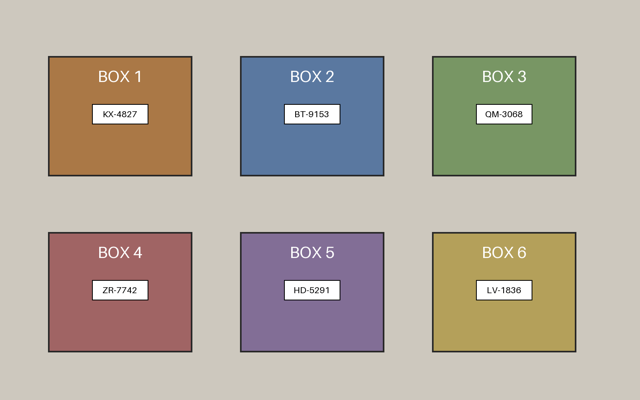

digits.mp4: 12 s, digits [7, 3, 9, 4, 8, 2].   long_digits.mp4: 61 s, 20 digits.


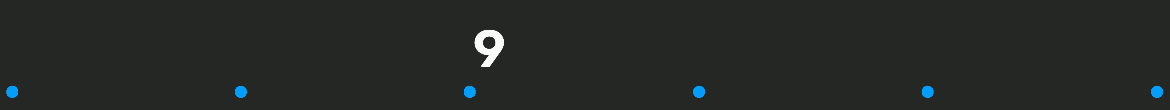

In [6]:
CODES = ["KX-4827", "BT-9153", "QM-3068", "ZR-7742", "HD-5291", "LV-1836"]

def make_label_image(path="labels.png", codes=CODES):
    im = Image.new("RGB", (1600, 1000), (205, 200, 190))
    d = ImageDraw.Draw(im)
    colours = [(170, 120, 70), (90, 120, 160), (120, 150, 100), (160, 100, 100), (130, 110, 150), (180, 160, 90)]
    small, big = ImageFont.load_default(size=22), ImageFont.load_default(size=40)
    for i, code_text in enumerate(codes):
        x, y = 120 + (i % 3) * 480, 140 + (i // 3) * 440
        d.rectangle([x, y, x + 360, y + 300], fill=colours[i], outline=(40, 40, 40), width=4)
        d.rectangle([x + 110, y + 120, x + 250, y + 170], fill="white", outline="black", width=2)
        d.text((x + 180, y + 145), code_text, font=small, fill="black", anchor="mm")
        d.text((x + 180, y + 50), f"BOX {i + 1}", font=big, fill="white", anchor="mm")
    im.save(path)
    return path

DIGITS = [7, 3, 9, 4, 8, 2]
LONG_DIGITS = [7, 3, 9, 4, 8, 2, 5, 1, 6, 3, 8, 4, 2, 9, 7, 5, 1, 6, 4, 3]

def make_digit_video(path, digits, gap, native_fps=24, visible_for=0.5):
    # Each digit is on screen for `visible_for` seconds; a new one starts every `gap` seconds.
    seconds = 1.0 + gap * len(digits)
    writer = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"mp4v"), native_fps, (640, 360))
    starts = [1.0 + i * gap for i in range(len(digits))]
    for i in range(int(seconds * native_fps)):
        t = i / native_fps
        frame = np.full((360, 640, 3), 40, np.uint8)
        cv2.circle(frame, (int(40 + 560 * t / seconds), 300), 20, (255, 160, 0), -1)      # a ball that crosses the screen
        for start, digit in zip(starts, digits):
            if start <= t < start + visible_for:
                cv2.putText(frame, str(digit), (270, 220), cv2.FONT_HERSHEY_SIMPLEX, 6, (255, 255, 255), 14)
        writer.write(frame)
    writer.release()
    return path, seconds

LABEL_IMAGE = make_label_image()
DIGIT_VIDEO, DIGIT_SECONDS = make_digit_video("digits.mp4", DIGITS, gap=1.8)
LONG_VIDEO, LONG_SECONDS = make_digit_video("long_digits.mp4", LONG_DIGITS, gap=3.0)

print(f"labels.png: codes {CODES}")
display(Image.open(LABEL_IMAGE).resize((640, 400)))
print(f"digits.mp4: {DIGIT_SECONDS:.0f} s, digits {DIGITS}.   long_digits.mp4: {LONG_SECONDS:.0f} s, {len(LONG_DIGITS)} digits.")
display(frame_strip(DIGIT_VIDEO, n=6, height=110))

### 1.7 One helper for every call: `ask()`

Every call in this notebook goes through the function below, so each parameter you will study is one named argument. It does the four steps of any VLM call:

1. **Build the conversation**: a system message, then a user message with the media first and the text after it. NVIDIA trained the model with media before text.
2. **Prepare inputs**: the processor resizes the image or frames to fit the vision token budget and converts everything to tensors.
3. **Generate**: the model produces up to `max_new_tokens` new tokens.
4. **Decode and measure**: turn tokens back into text and record token counts, seconds and peak GPU memory.

Video frames are read here with OpenCV instead of the library's built-in loader. The built-in loader depends on video packages that differ between Colab images, and reading frames yourself also shows exactly what `fps` does: it sets how many frames per second of video the model gets to see.

In [7]:
import functools, re, json
import pandas as pd
import matplotlib.pyplot as plt
from transformers.video_utils import VideoMetadata
from transformers.generation.streamers import BaseStreamer
pd.set_option("display.max_colwidth", 90)

PIXELS_PER_TOKEN = 32 * 32      # one vision token covers a 32 x 32 pixel patch
SYSTEM_PROMPT = "You are a helpful assistant."

# The reasoning add-on from NVIDIA's cosmos-reason2 utilities. It is appended to the user prompt.
REASONING_PROMPT = '''Answer the question using the following format:

<think>
Your reasoning.
</think>

Write your final answer immediately after the </think> tag.'''


@functools.lru_cache(maxsize=6)
def read_video(path, fps, clip=None):
    # Pick `fps` evenly spaced frames per second of video, from the whole file or from clip=(start_s, end_s).
    cap = cv2.VideoCapture(path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    native_fps = cap.get(cv2.CAP_PROP_FPS)
    first, last = (0, total - 1) if clip is None else (int(clip[0] * native_fps), min(int(clip[1] * native_fps), total) - 1)
    n = min(max(int((last - first + 1) / native_fps * fps), 4), 768, last - first + 1)   # same rule as the Qwen3-VL video processor
    wanted = np.linspace(first, last, n).round().astype(int)
    keep, frames = set(wanted.tolist()), []
    for i in range(last + 1):
        if not cap.grab():
            break
        if i in keep:
            frames.append(cv2.cvtColor(cap.retrieve()[1], cv2.COLOR_BGR2RGB))
    cap.release()
    # frames_indices keeps each frame's position in the original file, so timestamps stay true even for a clip
    meta = VideoMetadata(total_num_frames=total, fps=native_fps, frames_indices=wanted[:len(frames)].tolist(),
                         duration=total / native_fps, video_backend="opencv")
    return np.stack(frames), meta


def build_inputs(prompt, image=None, video=None, clip=None, fps=4, max_vision_tokens=1024, min_vision_tokens=16,
                 reasoning=False, system=SYSTEM_PROMPT, media_first=True):
    # Steps 1 and 2: conversation -> prompt text -> tensors. `image` can be one image or a list of images.
    images = [] if image is None else (list(image) if isinstance(image, (list, tuple)) else [image])
    media = [{"type": "image"} for _ in images] + ([{"type": "video"}] if video is not None else [])
    text = {"type": "text", "text": prompt + ("\n\n" + REASONING_PROMPT if reasoning else "")}
    conversation = [{"role": "system", "content": [{"type": "text", "text": system}]}] if system else []
    conversation.append({"role": "user", "content": media + [text] if media_first else [text] + media})
    prompt_text = processor.apply_chat_template(conversation, tokenize=False, add_generation_prompt=True)

    extra, n_frames = {}, None
    if images:
        extra["images"] = [(Image.open(i) if isinstance(i, str) else i).convert("RGB") for i in images]
    if video is not None:
        frames, meta = read_video(video, fps, clip)
        n_frames = len(frames)
        extra.update(videos=[frames], video_metadata=[meta], do_sample_frames=False)
    size = {"shortest_edge": min_vision_tokens * PIXELS_PER_TOKEN, "longest_edge": max_vision_tokens * PIXELS_PER_TOKEN}
    return processor(text=[prompt_text], return_tensors="pt", size=size, **extra), n_frames


def count_tokens(inputs):
    ids = inputs["input_ids"][0]
    vision = int(((ids == model.config.image_token_id) | (ids == model.config.video_token_id)).sum())
    return len(ids), vision


class FirstTokenTimer(BaseStreamer):
    # Records the moment the first new token arrives.
    def __init__(self):
        self.calls, self.at = 0, None
    def put(self, value):
        self.calls += 1
        if self.calls == 2:             # call 1 is the prompt itself, call 2 is the first generated token
            torch.cuda.synchronize()
            self.at = time.perf_counter()
    def end(self):
        pass


def ask(prompt, image=None, video=None, clip=None, fps=4, max_vision_tokens=1024, min_vision_tokens=16,
        reasoning=False, system=SYSTEM_PROMPT, media_first=True, max_new_tokens=256, do_sample=False, seed=0,
        streamer=None, use_model=None, **generate_kwargs):
    m = use_model or model
    t0 = time.perf_counter()
    inputs, n_frames = build_inputs(prompt, image, video, clip, fps, max_vision_tokens, min_vision_tokens, reasoning, system, media_first)
    inputs = inputs.to(m.device)
    t1 = time.perf_counter()
    n_in, n_vision = count_tokens(inputs)

    timer = FirstTokenTimer() if streamer is None else None
    torch.cuda.reset_peak_memory_stats()
    transformers.set_seed(seed)
    with torch.inference_mode():
        out = m.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=do_sample, streamer=streamer or timer, **generate_kwargs)
    torch.cuda.synchronize()
    t2 = time.perf_counter()

    new_tokens = out[0][n_in:]
    return {
        "text": processor.decode(new_tokens, skip_special_tokens=True).strip(),
        "input_tokens": n_in,
        "vision_tokens": n_vision,
        "output_tokens": len(new_tokens),
        "frames": n_frames,
        "prep_s": round(t1 - t0, 2),
        "gen_s": round(t2 - t1, 2),
        "first_token_s": round(timer.at - t1, 2) if timer and timer.at else None,
        "tokens_per_s": round(len(new_tokens) / (t2 - t1), 1),
        "peak_gpu_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2),
        "hit_limit": len(new_tokens) >= max_new_tokens,     # True means the answer was cut off
    }


STAT_KEYS = ["input_tokens", "vision_tokens", "output_tokens", "frames", "prep_s", "gen_s", "first_token_s", "tokens_per_s", "peak_gpu_gb", "hit_limit"]

def show(result):
    print(result["text"])
    print("\n" + "  ".join(f"{k}={result[k]}" for k in STAT_KEYS if result[k] is not None))

def final_answer(text):
    # The part after </think>. Empty if reasoning never finished.
    if "<think>" in text and "</think>" not in text:
        return ""
    return text.split("</think>")[-1].strip()

def parse_json(text):
    match = re.search(r"```(?:json)?\s*(.*?)```", text, re.S)
    return json.loads(match.group(1) if match else text)

_ = ask("Hi", image=ROBOT_IMAGE, max_new_tokens=4)      # warm-up: the first call on a fresh GPU is slow
print("Ready.")

Ready.


### 1.8 One helper for every measurement: `evaluate()`

To say a setting is "more accurate" you need questions with known answers and a way to score them. `evaluate()` takes a list of questions, runs each through `ask()` with whatever settings you pass, and returns the score and the time. `sweep()` repeats that over several values of one setting. Part 18 reuses both on your own data.

A question is a dictionary: the media, the question text `q`, and the `truth`. The truth can be `"yes"` or `"no"`, a number, a word that must appear, or a function that returns `True` for a right answer.

In [8]:
NUMBER_WORDS = {"zero": "0", "one": "1", "two": "2", "three": "3", "four": "4", "five": "5", "six": "6"}

def is_correct(answer, truth):
    if callable(truth):
        return bool(truth(answer))
    a, t = answer.lower().strip(), str(truth).lower()
    if t in ("yes", "no"):
        return a.startswith(t)
    if t.isdigit():
        return t in re.findall(r"\d+", a) or any(word in re.findall(r"[a-z]+", a) and digit == t for word, digit in NUMBER_WORDS.items())
    return t in a

def evaluate(questions, **settings):
    # Ask every question with the same settings. Returns a one-row summary and the per-question table.
    settings.setdefault("max_new_tokens", 800 if settings.get("reasoning") else 40)
    rows = []
    for item in questions:
        media = {k: v for k, v in item.items() if k not in ("q", "truth")}
        r = ask(item["q"], **{**media, **settings})
        answer = final_answer(r["text"])
        rows.append({"question": item["q"][:62], "truth": "(function)" if callable(item["truth"]) else item["truth"],
                     "answer": answer[:62] if answer else "(no answer: cut off while thinking)",
                     "correct": is_correct(answer, item["truth"]), "output_tokens": r["output_tokens"],
                     "gen_s": r["gen_s"], "peak_gpu_gb": r["peak_gpu_gb"]})
    df = pd.DataFrame(rows)
    summary = {"correct": int(df["correct"].sum()), "questions": len(df), "accuracy": round(float(df["correct"].mean()), 2),
               "total_gen_s": round(float(df["gen_s"].sum()), 2), "avg_output_tokens": round(float(df["output_tokens"].mean()), 1),
               "peak_gpu_gb": float(df["peak_gpu_gb"].max())}
    return summary, df

# Shared test prompts and scorers, used by several parts
READ_CODES = ("Read the code printed on the white label of each box, from BOX 1 to BOX 6. "
              "Answer with the six codes separated by commas, nothing else.")
LIST_DIGITS = ("Large white digits flash on the screen one at a time during this video. "
               "List every digit that appears, in order, separated by commas. Answer with the digits only.")

def codes_read(text):
    return sum(code_text in text for code_text in CODES)      # how many of the six codes were read correctly

def digits_said(text):
    return [int(x) for x in re.findall(r"\d", text)]

# Six questions about the warehouse clip, with answers checked by eye against the footage (Parts 11 and 13)
WAREHOUSE_QUESTIONS = [
    dict(q="How many different people appear in this video? Answer with a number.", truth="2"),
    dict(q="Does every person in this video wear a hard hat? Answer yes or no.", truth="no"),
    dict(q="Is a cardboard box left lying on the floor at some point in this video? Answer yes or no.", truth="yes"),
    dict(q="One person picks a cardboard box up off the floor. Is that person wearing a high-visibility vest? Answer yes or no.", truth="no"),
    dict(q="There are signs with single letters on the shelf posts. Which letters are shown? Answer with the letters only.",
         truth=lambda a: sorted(set(re.findall(r"\b([a-z])\b", a.lower()))) == list("cdef")),
    dict(q="What colour is the hard hat worn by the first worker? One word.", truth="yellow"),
]

def sweep(questions, name, values, **fixed):
    # Run evaluate() once per value of one setting and stack the summaries.
    return pd.DataFrame([{name: v, **evaluate(questions, **{**fixed, name: v})[0]} for v in values])

def two_panel(df, x, title):
    # Accuracy and time against one setting.
    fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.2))
    time_col = "gen_s" if "gen_s" in df else "total_gen_s"
    a.plot(df[x], df["accuracy"] * 100, marker="o", color="#2a7f62")
    a.set_ylim(-5, 105); a.set_ylabel("accuracy (%)"); a.set_xlabel(x); a.set_title("Accuracy")
    b.plot(df[x], df[time_col], marker="o", color="#b5532a")
    b.set_ylim(bottom=0); b.set_ylabel("generation time (s)"); b.set_xlabel(x); b.set_title("Response time")
    for ax in (a, b):
        ax.set_xscale("log", base=2); ax.set_xticks(list(df[x])); ax.set_xticklabels([str(v) for v in df[x]]); ax.grid(alpha=0.3)
    fig.suptitle(title); fig.tight_layout(); plt.show()

## Part 2. First calls

### 2.1 An image question

In [9]:
r = ask("Describe this image in two sentences.", image=ROBOT_IMAGE)
show(r)

An empty gray woven basket sits on a wooden table, accompanied by a roll of blue tape and two black prosthetic hands positioned symmetrically on either side of the basket.

input_tokens=1028  vision_tokens=1000  output_tokens=35  prep_s=0.11  gen_s=0.35  first_token_s=0.06  tokens_per_s=100.4  peak_gpu_gb=4.48  hit_limit=False


Read the stats line under the answer. You will use it in every part:

- `input_tokens`: everything the model read. `vision_tokens` is the share that came from the picture. Text is a small fraction.
- `output_tokens`: what the model wrote.
- `prep_s`: seconds to load and resize the media. `gen_s`: seconds the model spent reading the input and writing the answer. `first_token_s` is the part of `gen_s` that passed before the first word appeared (Part 8).
- `peak_gpu_gb`: highest GPU memory during the call.
- `hit_limit`: `True` if the answer stopped because it reached `max_new_tokens`.

### 2.2 A video question

In [10]:
display(Video(DASHCAM_VIDEO, embed=True, width=480))
r = ask("Caption the video in detail.", video=DASHCAM_VIDEO, fps=4, max_new_tokens=400)
show(r)

The video captures a scene from the perspective of a vehicle's dashboard camera, providing a clear view of a residential neighborhood on a sunny day. The sky is bright blue with scattered clouds, indicating favorable weather conditions. The neighborhood is lined with houses featuring pitched roofs and various architectural styles. Many homes have driveways and garages, some of which are occupied by vehicles.

Several cars are parked along the street and driveways, including sedans, SUVs, and hatchbacks. The vehicles are positioned at different angles, suggesting that residents have ample space for parking. Trees with lush green foliage are interspersed throughout the neighborhood, adding to the suburban ambiance. Some trees have vibrant red leaves, indicating that it might be late summer or early autumn.

Power lines run parallel to the street, supported by poles that are evenly spaced. Utility poles and transformers are visible, contributing to the infrastructure of the area. The stre

A caption reads fluently whether or not it is true. Compare it with the clip above before you trust it. Part 12 shows how to test that systematically.

## Part 3. What is inside a call

The model never sees your Python objects. The processor writes one long prompt in the model's chat format, with a block of placeholder tokens where the picture goes. Each placeholder is later replaced by one patch of the image. Printing the prompt (with the placeholders collapsed) makes the structure visible.

In [11]:
def show_prompt(inputs):
    text = processor.decode(inputs["input_ids"][0])
    text = re.sub(r"(<\|(image|video)_pad\|>)+", lambda m: f"[{m.group(0).count('_pad')} vision tokens]", text)
    print(text)

inputs, _ = build_inputs("What objects are on the table?", image=ROBOT_IMAGE, max_vision_tokens=1024)
show_prompt(inputs)
print("\ntotal, vision tokens:", count_tokens(inputs))

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
<|vision_start|>[1000 vision tokens]<|vision_end|>What objects are on the table?<|im_end|>
<|im_start|>assistant


total, vision tokens: (1028, 1000)


For video, the processor also writes a timestamp in front of each group of frames. Those timestamps are how the model can tell you *when* something happened.

In [12]:
inputs, n_frames = build_inputs("Caption the video in detail.", video=DASHCAM_VIDEO, fps=4)
print("frames sent:", n_frames)
show_prompt(inputs)

frames sent: 10
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
<0.1 seconds><|vision_start|>[91 vision tokens]<|vision_end|><0.6 seconds><|vision_start|>[91 vision tokens]<|vision_end|><1.1 seconds><|vision_start|>[91 vision tokens]<|vision_end|><1.6 seconds><|vision_start|>[91 vision tokens]<|vision_end|><2.1 seconds><|vision_start|>[91 vision tokens]<|vision_end|>Caption the video in detail.<|im_end|>
<|im_start|>assistant



Three facts to carry forward:

1. **Cost is counted in tokens.** Time and memory grow with `input_tokens + output_tokens`.
2. **Vision dominates the input.** One vision token covers a 32 x 32 pixel patch, so a 1024 x 1024 image is about 1,024 tokens. In video, two neighbouring frames share one set of tokens.
3. **You control both sides.** The vision budget and `fps` set the input size. `max_new_tokens` caps the output size.

## Part 4. `max_new_tokens`: output length and time

`max_new_tokens` is a hard cap on how many tokens the model may write. It does not make the model write more. The model stops by itself when it finishes. The cap only matters when it is lower than the answer the model wanted to give, and then the answer is cut mid-sentence.

In [13]:
rows = []
for cap in (16, 64, 256, 1024):
    r = ask("Describe this image in detail.", image=ROBOT_IMAGE, max_new_tokens=cap)
    rows.append({"max_new_tokens": cap, "output_tokens": r["output_tokens"], "gen_s": r["gen_s"],
                 "hit_limit": r["hit_limit"], "answer ends with": "..." + r["text"][-55:]})
pd.DataFrame(rows)

,max_new_tokens,output_tokens,gen_s,hit_limit,answer ends with
0,16,16,0.19,True,"...a scene set on a wooden table, which serves as the main"
1,64,64,0.59,True,...th the warm tones of the wooden table.\n\nAdjacent to the
2,256,239,2.05,False,... to embark on a task involving the basket and the tape.
3,1024,239,2.05,False,... to embark on a task involving the basket and the tape.


What to read in the table:

- `gen_s` rises with `output_tokens`, because the model writes one token per step.
- Rows with `hit_limit = True` end mid-sentence.
- Once the cap is above the natural answer length, raising it changes nothing: the last two rows are the same answer in the same time.

**Rule:** set `max_new_tokens` above the longest answer you expect, and check `hit_limit`. NVIDIA recommends 4096 or more when reasoning is on (Part 9), because a cut-off reasoning trace never reaches the answer.

## Part 5. Vision token budget: image detail, accuracy and time

### 5.1 The budget

Before the model sees an image, the processor resizes it so the number of vision tokens falls between a minimum and a maximum. In `ask()` these are `min_vision_tokens` and `max_vision_tokens`. Under the hood they set the processor's `size` (`shortest_edge` and `longest_edge`, measured in pixels: tokens x 1024). Older Qwen code calls the same thing `min_pixels` and `max_pixels`.

A smaller budget means a smaller picture: faster, less memory, and fine detail is lost. The test is the label image from Part 1: read six small printed codes.

Prompt: Read the code printed on the white label of each box, from BOX 1 to BOX 6. Answer with the six codes separated by commas, nothing else. 



,max_vision_tokens,vision_tokens,codes_correct,accuracy,gen_s,peak_gpu_gb,answer
0,64,60,1/6,0.166667,0.38,4.29,"XX-4827, BT-0191, OA-3008, ZW-7742, HD-5291, LV-5406"
1,128,112,3/6,0.500000,0.38,4.30,"IX-4327, BT-9123, OM-3068, ZR-7742, HD-5291, LV-1836"
2,256,240,6/6,1.000000,0.39,4.33,"KX-4827,BT-9153,QM-3068,ZR-7742,HD-5291,LV-1836"
3,512,476,6/6,1.000000,0.39,4.39,"KX-4827,BT-9153,QM-3068,ZR-7742,HD-5291,LV-1836"
4,1024,1000,6/6,1.000000,0.41,4.48,"KX-4827,BT-9153,QM-3068,ZR-7742,HD-5291,LV-1836"
5,2048,1550,6/6,1.000000,0.47,4.61,"KX-4827, BT-9153, QM-3068, ZR-7742, HD-5291, LV-1836"


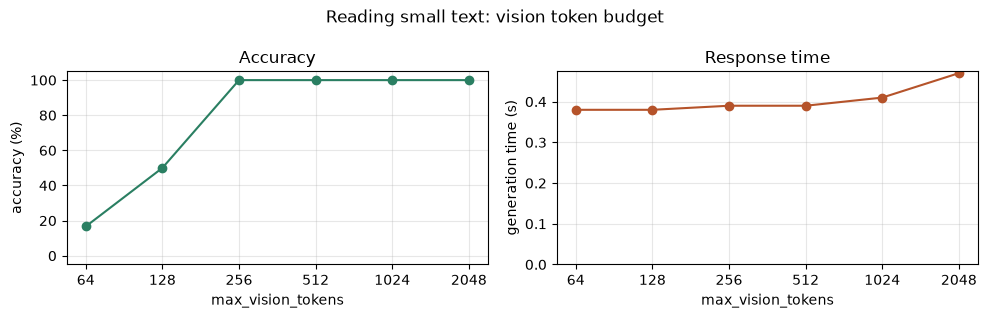

In [14]:
print("Prompt:", READ_CODES, "\n")
rows = []
for budget in (64, 128, 256, 512, 1024, 2048):
    r = ask(READ_CODES, image=LABEL_IMAGE, max_vision_tokens=budget, max_new_tokens=80)
    rows.append({"max_vision_tokens": budget, "vision_tokens": r["vision_tokens"], "codes_correct": f"{codes_read(r['text'])}/6",
                 "accuracy": codes_read(r["text"]) / 6, "gen_s": r["gen_s"], "peak_gpu_gb": r["peak_gpu_gb"], "answer": r["text"]})
vision_df = pd.DataFrame(rows)
display(vision_df)
two_panel(vision_df, "max_vision_tokens", "Reading small text: vision token budget")

What to read here:

- At the smallest budgets the image is shrunk until the printed codes blur, and the model guesses characters. It does not say "I cannot read this". It returns confident wrong codes. **A budget that is too low fails silently.**
- Past the point where the text is legible, more tokens add time and memory and no accuracy.
- `vision_tokens` stops growing once the budget exceeds the image's own size, because the processor does not enlarge an image to fill the budget.

**Rule:** pick the smallest budget at which your smallest important detail is still readable. Scene-level questions ("is there a person?") need few tokens. Small text, gauges and distant objects need many.

### 5.2 Cropping: spend the tokens where the detail is

The budget is spread over the whole picture. If you know where the detail is, cut that region out and send it alone: the same number of tokens now covers a smaller area, so each token sees finer detail. The cell compares the whole label image at 128 tokens, the same image as two halves at 128 tokens each, and the whole image at 256 tokens.

In [15]:
READ_ANY = "Read the code printed on the white label of each box. Answer with the codes separated by commas, nothing else."
label = Image.open(LABEL_IMAGE)
top, bottom = label.crop((0, 0, 1600, 500)), label.crop((0, 500, 1600, 1000))

whole_128 = ask(READ_ANY, image=label, max_vision_tokens=128, max_new_tokens=80)
halves = [ask(READ_ANY, image=part, max_vision_tokens=128, max_new_tokens=80) for part in (top, bottom)]
whole_256 = ask(READ_ANY, image=label, max_vision_tokens=256, max_new_tokens=80)

pd.DataFrame([
    {"approach": "whole image, 128 tokens", "calls": 1, "vision_tokens": whole_128["vision_tokens"],
     "codes_correct": f"{codes_read(whole_128['text'])}/6", "gen_s": whole_128["gen_s"]},
    {"approach": "two halves, 128 tokens each", "calls": 2, "vision_tokens": sum(h["vision_tokens"] for h in halves),
     "codes_correct": f"{sum(codes_read(h['text']) for h in halves)}/6", "gen_s": round(sum(h["gen_s"] for h in halves), 2)},
    {"approach": "whole image, 256 tokens", "calls": 1, "vision_tokens": whole_256["vision_tokens"],
     "codes_correct": f"{codes_read(whole_256['text'])}/6", "gen_s": whole_256["gen_s"]},
])

,approach,calls,vision_tokens,codes_correct,gen_s
0,"whole image, 128 tokens",1,112,2/6,0.38
1,"two halves, 128 tokens each",2,240,6/6,0.39
2,"whole image, 256 tokens",1,240,5/6,0.39


Compare the first two rows: the picture and the per-call budget are the same, and only the framing changed. Then compare the last two rows, which spend the same total tokens. Cropping costs an extra call, and in return each call sees the detail at twice the scale.

**Rule:** when a detail is too small, crop before you raise the budget. A detector or a fixed region of interest (a gauge, a label, a doorway) tells you where to crop.

## Part 6. Video: `fps`, the shared frame budget, splitting a long video

### 6.1 `fps`: how often the model looks

`fps` is the number of frames per second of video handed to the model. It is separate from the frame rate the file was recorded at. NVIDIA trained Cosmos Reason 2 at `fps=4` and recommends that value.

Lower `fps` means fewer frames and a faster call. The risk is that anything shorter than the gap between sampled frames can be missed. The digit clip from Part 1 is built to show that: each digit is on screen for half a second.

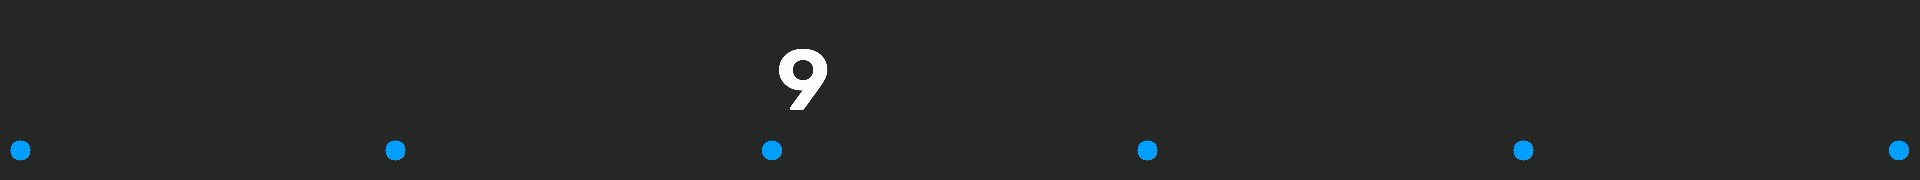

Above: every second frame the model receives at fps=1. Count how many digits made it in.
Prompt: Large white digits flash on the screen one at a time during this video. List every digit that appears, in order, separated by commas. Answer with the digits only. 



,fps,frames,vision_tokens,accuracy,prep_s,gen_s,peak_gpu_gb,answer
0,0.5,5,660,0.0,0.02,0.10,4.42,"3, 2, 1"
1,1.0,11,1080,0.0,0.04,0.39,4.51,"7, 9, 8, 10, 11, 12, 13, 14, 15, 16, 17,"
2,2.0,23,1008,1.0,0.10,0.19,4.50,"7, 3, 9, 4, 8, 2"
3,4.0,47,768,1.0,0.11,0.20,4.47,"7, 3, 9, 4, 8, 2"
4,8.0,94,846,1.0,0.12,0.21,4.52,"7, 3, 9, 4, 8, 2"


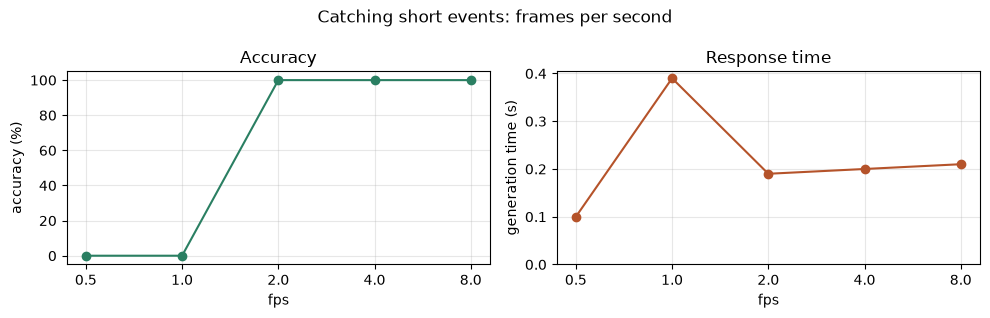

In [16]:
frames, _ = read_video(DIGIT_VIDEO, fps=1)
display(Image.fromarray(np.hstack([frames[i][::2, ::2] for i in range(0, len(frames), 2)])))
print("Above: every second frame the model receives at fps=1. Count how many digits made it in.")

print("Prompt:", LIST_DIGITS, "\n")
rows = []
for fps in (0.5, 1, 2, 4, 8):
    r = ask(LIST_DIGITS, video=DIGIT_VIDEO, fps=fps, max_vision_tokens=2048, max_new_tokens=40)
    rows.append({"fps": fps, "frames": r["frames"], "vision_tokens": r["vision_tokens"],
                 "accuracy": float(digits_said(r["text"]) == DIGITS),      # all six, in order, nothing extra
                 "prep_s": r["prep_s"], "gen_s": r["gen_s"], "peak_gpu_gb": r["peak_gpu_gb"], "answer": r["text"]})
fps_df = pd.DataFrame(rows)
display(fps_df)
two_panel(fps_df, "fps", "Catching short events: frames per second")

What to read here:

- At low `fps` the sampled frames step over most of the digits. The model reports the few it saw, or invents a sequence. Again, it does not warn you.
- Once the gap between frames is shorter than the event (0.5 s here, so 2 fps and up), every digit lands in at least one frame and the answer is right.
- `frames` doubles with each row, but `vision_tokens` does not. That is the shared budget, next.

**Rule:** choose `fps` from the shortest event you must catch. You need at least one sampled frame inside it, and two is safer. Use 4 when unsure, since that is what the model was trained on.

### 6.2 The frame budget is shared

For video, `max_vision_tokens` is one budget for the **whole clip**. More frames means fewer pixels per frame. So with a fixed budget, raising `fps` trades sharpness for coverage in time. The next cell fixes `fps=4` and changes only the budget.

In [17]:
rows = []
for budget in (64, 128, 256, 512, 2048):
    r = ask(LIST_DIGITS, video=DIGIT_VIDEO, fps=4, max_vision_tokens=budget, max_new_tokens=40)
    rows.append({"max_vision_tokens": budget, "frames": r["frames"], "vision_tokens": r["vision_tokens"],
                 "tokens_per_frame_pair": round(r["vision_tokens"] / (r["frames"] / 2), 1),
                 "accuracy": float(digits_said(r["text"]) == DIGITS), "gen_s": r["gen_s"], "answer": r["text"]})
pd.DataFrame(rows)

,max_vision_tokens,frames,vision_tokens,tokens_per_frame_pair,accuracy,gen_s,answer
0,64,47,24,1.0,0.0,0.36,"7, 2, 1, 0, 9, 8, 6, 5, 4, 3, 1, 2, 0, 9"
1,128,47,48,2.0,0.0,0.36,"7, 3, 8, 2, 8, 2, 8, 2, 8, 2, 8, 2, 8, 2"
2,256,47,72,3.1,0.0,0.36,"7, 3, 4, 8, 2, 1, 6, 5, 9, 0, 1, 8, 2, 1"
3,512,47,192,8.2,1.0,0.17,"7, 3, 9, 4, 8, 2"
4,2048,47,768,32.7,1.0,0.19,"7, 3, 9, 4, 8, 2"


`frames` is the same in every row, and `tokens_per_frame_pair` shows how much picture each moment of the video gets. At the smallest budgets a frame pair is left with a handful of tokens, the digits become unreadable, and the model makes a sequence up. The clip has enough frames and still fails, because each frame is too coarse.

### 6.3 Long video: split it into clips

A one minute video at 4 fps is 240 frames, and a lot happens in it. One call has to spread its budget over every frame and keep track of every event. The video version of cropping is to cut the timeline into clips and ask about each one. `ask()` takes `clip=(start_seconds, end_seconds)` for this, and the timestamps the model sees stay true to the original file.

The test: list all twenty digits in the one minute clip. First in a single call. Then split three ways, to show that how you split matters as much as whether you split.

In [18]:
def list_digits_in_clips(n_clips, budget):
    found, tokens, seconds = [], 0, 0.0
    for k in range(n_clips):
        clip = (k * LONG_SECONDS / n_clips, (k + 1) * LONG_SECONDS / n_clips)
        r = ask(LIST_DIGITS, video=LONG_VIDEO, clip=clip, fps=4, max_vision_tokens=budget, max_new_tokens=40)
        found += digits_said(r["text"]); tokens += r["vision_tokens"]; seconds += r["gen_s"]
    return found, tokens, seconds

single = ask(LIST_DIGITS, video=LONG_VIDEO, fps=4, max_vision_tokens=4096, max_new_tokens=120)
runs = [("one call, 4096 tokens", digits_said(single["text"]), single["vision_tokens"], single["gen_s"])]
for n_clips, budget in ((8, 512), (12, 512), (8, 128)):
    runs.append((f"{n_clips} clips of {LONG_SECONDS / n_clips:.1f} s, {budget} tokens each", *list_digits_in_clips(n_clips, budget)))

print("truth:", LONG_DIGITS, f"({len(LONG_DIGITS)} digits)")
pd.DataFrame([{"approach": name, "vision_tokens_total": tokens, "gen_s_total": round(seconds, 2), "exact": found == LONG_DIGITS,
               "digits_returned": len(found), "answer": str(found)[:95]} for name, found, tokens, seconds in runs])

truth: [7, 3, 9, 4, 8, 2, 5, 1, 6, 3, 8, 4, 2, 9, 7, 5, 1, 6, 4, 3] (20 digits)


,approach,vision_tokens_total,gen_s_total,exact,digits_returned,answer
0,"one call, 4096 tokens",1830,1.15,False,40,"[7, 3, 9, 4, 8, 2, 5, 1, 6, 3, 8, 4, 2, 9, 7, 5, 1, 6, 3, 8, 4, 2, 9, 7, 5, 1, 6, 3, 8..."
1,"8 clips of 7.6 s, 512 tokens each",1800,0.62,True,20,"[7, 3, 9, 4, 8, 2, 5, 1, 6, 3, 8, 4, 2, 9, 7, 5, 1, 6, 4, 3]"
2,"12 clips of 5.1 s, 512 tokens each",2160,0.68,False,22,"[7, 3, 9, 4, 4, 8, 2, 5, 1, 6, 6, 3, 8, 4, 2, 9, 7, 5, 1, 6, 4, 3]"
3,"8 clips of 7.6 s, 128 tokens each",240,2.03,False,77,"[7, 3, 9, 6, 5, 4, 8, 1, 0, 2, 7, 3, 9, 6, 4, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 1..."


What to read here:

- **One call** gets most of the sequence and then loses its place, repeating or inventing digits. Check `digits_returned` against the true count of twenty.
- **Eight clips at 512 tokens** uses about the same total tokens as the single call. Each call has only two or three digits to report, which is a much easier job.
- **Twelve clips** has more calls and more tokens, and a different failure: a clip boundary lands in the middle of a digit's half second on screen, so both neighbouring clips report it and it is counted twice. Look for doubled digits in the answer.
- **Eight clips at 128 tokens** starves each clip of detail, and the model invents sequences, exactly as in 6.2.

**Rule:** split a long video into clips short enough to hold a few events each, give each clip enough tokens to be legible, and decide what happens at the boundaries. Overlap the clips and remove duplicates, or cut where nothing is happening. Then test the clip length on footage with a known answer, because the best value is not the largest or the smallest.

For a long video you have three levers, and each one costs something:

| Lever | Gain | Cost |
|---|---|---|
| Lower `fps` | fewer tokens | short events missed |
| Lower `max_vision_tokens` | fewer tokens | blurrier frames |
| Split into clips, one call per clip | each clip keeps full detail | more calls, and the model cannot connect events across clips |

## Part 7. Context window: counting what you send

The **context window** is the most tokens the model can hold in one call: everything you send plus everything it writes.

`input_tokens + max_new_tokens <= context window`

In [19]:
print("Model limit (max_position_embeddings):", f"{model.config.text_config.max_position_embeddings:,} tokens")

Model limit (max_position_embeddings): 262,144 tokens


The model card describes this as long-context understanding up to 256K input tokens. In practice you hit two earlier limits:

- **GPU memory and time.** Both grow with the token count. A small GPU runs out of memory long before 256K.
- **The server's own limit.** A vLLM server is started with `--max-model-len`, and NVIDIA recommends 8192 to 16384 for this model to avoid running out of memory. A request whose input is longer than that number is rejected with an error (Part 17).

So before sending a long video, count. `build_inputs()` prepares a call without running the model, which makes counting cheap. The cell below counts tokens for several settings and checks them against a 16,384 token window with 1,024 tokens reserved for the answer. The last row is the one minute clip at a generous budget, which does not fit.

In [20]:
WINDOW, RESERVED_FOR_ANSWER = 16384, 1024

rows = []
for label_text, kwargs in [
    ("robot image, budget 256",   dict(image=ROBOT_IMAGE, max_vision_tokens=256)),
    ("robot image, budget 1024",  dict(image=ROBOT_IMAGE, max_vision_tokens=1024)),
    ("robot image, budget 4096",  dict(image=ROBOT_IMAGE, max_vision_tokens=4096)),
    ("12 s video, 2 fps, budget 2048", dict(video=DIGIT_VIDEO, fps=2, max_vision_tokens=2048)),
    ("12 s video, 8 fps, budget 2048", dict(video=DIGIT_VIDEO, fps=8, max_vision_tokens=2048)),
    ("12 s video, 8 fps, budget 16384", dict(video=DIGIT_VIDEO, fps=8, max_vision_tokens=16384)),
    ("61 s video, 8 fps, budget 65536", dict(video=LONG_VIDEO, fps=8, max_vision_tokens=65536)),
]:
    inputs, n_frames = build_inputs("Describe what you see.", **kwargs)
    total, vision = count_tokens(inputs)
    rows.append({"call": label_text, "frames": n_frames or "-", "input_tokens": total, "vision_tokens": vision,
                 "fits_16k_window": total + RESERVED_FOR_ANSWER <= WINDOW})
pd.DataFrame(rows)

,call,frames,input_tokens,vision_tokens,fits_16k_window
0,"robot image, budget 256",-,266,240,True
1,"robot image, budget 1024",-,1026,1000,True
2,"robot image, budget 4096",-,2246,2220,True
3,"12 s video, 2 fps, budget 2048",23,1130,1008,True
4,"12 s video, 8 fps, budget 2048",94,1253,846,True
5,"12 s video, 8 fps, budget 16384",94,7598,7191,True
6,"61 s video, 8 fps, budget 65536",488,31460,29280,False


Now the cost side. The same image question at growing input sizes, with the answer length held short, isolates what input tokens cost in time and memory.

In [21]:
rows = []
for budget in (256, 1024, 2048, 4096):
    r = ask("What colour is the tape? One word.", image=ROBOT_IMAGE, max_vision_tokens=budget, max_new_tokens=8)
    rows.append({"max_vision_tokens": budget, "input_tokens": r["input_tokens"], "gen_s": r["gen_s"],
                 "peak_gpu_gb": r["peak_gpu_gb"], "answer": r["text"]})
pd.DataFrame(rows)

,max_vision_tokens,input_tokens,gen_s,peak_gpu_gb,answer
0,256,270,0.03,4.33,Blue
1,1024,1030,0.07,4.48,Blue
2,2048,2025,0.13,4.69,Blue
3,4096,2250,0.15,4.74,Blue


The answer is identical in every row. Only the time and memory changed. Input tokens you do not need are pure cost.

**Rule:** budget the window before the call. Reserve room for the answer first (more if reasoning is on), then spend what is left on vision.

## Part 8. Where the time goes: the first token against the rest

A call has two phases, and different settings drive each one:

1. **Before the first token.** The model reads the whole input: all vision tokens and the prompt. This time depends on `input_tokens`, so on the vision budget and `fps`.
2. **After the first token.** The model writes the answer one token at a time. This time depends on `output_tokens`, so on answer length, `max_new_tokens` and reasoning.

`ask()` records the split as `first_token_s`. The cell runs a short answer and a long answer at three input sizes.

,call,input_tokens,output_tokens,first_token_s,rest_s,gen_s
0,"267 in, short answer",267,8,0.03,0.06,0.09
1,"267 in, long answer",267,200,0.02,1.69,1.71
2,"1027 in, short answer",1027,8,0.06,0.06,0.12
3,"1027 in, long answer",1027,200,0.06,1.68,1.74
4,"2247 in, short answer",2247,8,0.14,0.06,0.20
5,"2247 in, long answer",2247,200,0.14,1.68,1.82


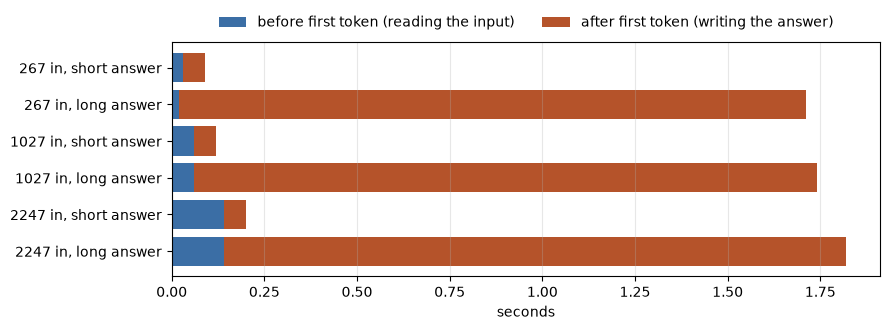

In [22]:
rows = []
for budget in (256, 1024, 4096):
    for cap, kind in ((8, "short answer"), (200, "long answer")):
        r = ask("Describe this image in detail.", image=ROBOT_IMAGE, max_vision_tokens=budget, max_new_tokens=cap)
        rows.append({"call": f"{r['input_tokens']} in, {kind}", "input_tokens": r["input_tokens"], "output_tokens": r["output_tokens"],
                     "first_token_s": r["first_token_s"], "rest_s": round(r["gen_s"] - r["first_token_s"], 2), "gen_s": r["gen_s"]})
time_df = pd.DataFrame(rows)
display(time_df)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(time_df["call"], time_df["first_token_s"], color="#3b6ea5", label="before first token (reading the input)")
ax.barh(time_df["call"], time_df["rest_s"], left=time_df["first_token_s"], color="#b5532a", label="after first token (writing the answer)")
ax.invert_yaxis(); ax.set_xlabel("seconds"); ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
fig.tight_layout(); plt.show()

What to read here:

- `first_token_s` grows down the table with `input_tokens` and is the same for the short and the long answer at each input size.
- `rest_s` depends only on how much was written. For a long answer it is most of the call.
- So there are two different ways a call is slow. A short answer that is slow has too many input tokens: cut the vision budget or `fps`. A call that is slow because it writes a lot needs a shorter answer: ask for one word, a number or compact JSON, and keep reasoning off unless you need it.

**Rule:** to speed up a call, first find which phase dominates. For a yes or no check on a camera frame it is the input. For captions and reasoning it is the output.

## Part 9. Reasoning mode: accuracy against time

Cosmos Reason 2 can think step by step before it answers. You switch this on through the prompt: NVIDIA's utilities append a short instruction asking for the reasoning inside `<think>...</think>` followed by the final answer. In `ask()` that is `reasoning=True`. (The model card shows a variant of the same instruction placed in the system prompt, with the answer wrapped in `<answer>` tags.)

One question first, both ways.

In [23]:
SUM_QUESTION = "Large white digits flash on the screen one at a time. What is the sum of all the digits shown? Give the number."
print("Correct answer:", sum(DIGITS), "\n")

print("--- reasoning off ---")
show(ask(SUM_QUESTION, video=DIGIT_VIDEO, max_new_tokens=64))
print("\n--- reasoning on ---")
show(ask(SUM_QUESTION, video=DIGIT_VIDEO, reasoning=True, max_new_tokens=800))

Correct answer: 33 

--- reasoning off ---
45

input_tokens=673  vision_tokens=432  output_tokens=3  frames=47  prep_s=0.04  gen_s=0.06  first_token_s=0.04  tokens_per_s=49.9  peak_gpu_gb=4.4  hit_limit=False

--- reasoning on ---


<think>
Okay, let's see. The user is asking for the sum of all the digits shown in the video. The video shows that large white digits flash on the screen one at a time. The digits shown are 7, 3, 9, 4, 8, 2. Wait, let me check again.

Looking back at the video: "Large white digits flash on the screen one at a time. The digits flash as follows: 7, 3, 9, 4, 8, 2." So the digits are 7, 3, 9, 4, 8, 2. The question is asking for the sum of all these digits. 

Let me add them up. Starting with 7 + 3 = 10. Then 10 + 9 = 19. Next, 19 +4 = 23. Then 23 +8 = 31. Finally, 31 +2 = 33. So the sum should be 33. 

I need to make sure there are no other digits shown. The video lists six digits: 7, 3, 9, 4, 8, 2. No other digits are present. So the answer is 33.
</think>

33

input_tokens=699  vision_tokens=432  output_tokens=277  frames=47  prep_s=0.02  gen_s=2.35  first_token_s=0.04  tokens_per_s=118.0  peak_gpu_gb=4.41  hit_limit=False


Now a small test set of five questions with known answers. Some need several steps (read, then compare or add). Some are single-step. Each is asked with reasoning off and on.

In [24]:
REASONING_QUESTIONS = [
    dict(video=DIGIT_VIDEO, q=SUM_QUESTION, truth="33"),
    dict(image=LABEL_IMAGE, q="Each box has a white label with a code. Which box number has the code whose last two digits form the largest number?", truth="5"),
    dict(video=DIGIT_VIDEO, q="Large white digits flash on the screen one at a time. Which digit appears immediately after the digit 9?", truth="4"),
    dict(image=LABEL_IMAGE, q="Read the codes on the white labels. How many of the six codes contain the digit 8?", truth="4"),
    dict(image=ROBOT_IMAGE, q="Which robot hand is closer to the blue tape, the one on the left of the image or the one on the right? Answer left or right.",
         truth=lambda a: "right" in a.lower() and "left" not in a.lower()),
]

summaries = []
for reasoning in (False, True):
    summary, table = evaluate(REASONING_QUESTIONS, reasoning=reasoning)
    summaries.append({"reasoning": reasoning, **summary})
    print(f"\nreasoning = {reasoning}")
    display(table[["question", "truth", "answer", "correct", "output_tokens", "gen_s"]])
pd.DataFrame(summaries)


reasoning = False


,question,truth,answer,correct,output_tokens,gen_s
0,Large white digits flash on the screen one at a time. What is,33,45,False,3,0.06
1,Each box has a white label with a code. Which box number has t,5,Box 2,False,4,0.09
2,Large white digits flash on the screen one at a time. Which di,4,4,True,2,0.05
3,Read the codes on the white labels. How many of the six codes,4,"Only BOX 1 contains the digit 8 in its code, which is KX-4827.",False,24,0.26
4,"Which robot hand is closer to the blue tape, the one on the le",(function),The robot hand on the left of the image,False,10,0.14



reasoning = True


,question,truth,answer,correct,output_tokens,gen_s
0,Large white digits flash on the screen one at a time. What is,33,33,True,277,2.35
1,Each box has a white label with a code. Which box number has t,5,BOX 5,True,289,2.46
2,Large white digits flash on the screen one at a time. Which di,4,8,False,343,2.90
3,Read the codes on the white labels. How many of the six codes,4,3,False,488,4.13
4,"Which robot hand is closer to the blue tape, the one on the le",(function),(no answer: cut off while thinking),False,800,6.72


,reasoning,correct,questions,accuracy,total_gen_s,avg_output_tokens,peak_gpu_gb
0,False,1,5,0.2,0.60,8.6,4.48
1,True,2,5,0.4,18.56,439.4,4.52


What to read here:

- **Time.** Compare `avg_output_tokens` and `total_gen_s` between the two rows. Reasoning writes hundreds of tokens where a direct answer writes a handful, and time follows the tokens.
- **Accuracy.** Look at which questions flip from wrong to right. Multi-step questions (sum, compare) are where thinking has room to help. A question the model can answer at a glance gains nothing and can even go wrong after a long detour.
- **Cut-offs.** A row with no final answer is a reasoning trace that ran past `max_new_tokens`. All that time was spent and nothing usable came back. This is why NVIDIA recommends 4096 or more output tokens with reasoning. The cap here is 800 to keep the notebook quick on a small GPU.
- Five questions is a demonstration, not a benchmark. Run your own questions before deciding (Part 18).

**Rule:** turn reasoning on for questions that need steps, give it a generous `max_new_tokens`, and always check that a final answer came back. Leave it off for simple perception and for anything latency-bound.

## Part 10. Sampling: `temperature`, `top_p`, `top_k`, `repetition_penalty`, `seed`

At each step the model has a probability for every possible next token. The decoding settings decide how one is picked.

| Setting | Effect |
|---|---|
| `do_sample=False` | Greedy: always take the most likely token. Same input, same output. Everything above used this, so the experiments were repeatable. |
| `do_sample=True` | Draw the token at random according to the probabilities, shaped by the settings below. |
| `temperature` | Below 1 sharpens the distribution (safer, more repeatable). Above 1 flattens it (more varied, more errors). |
| `top_k` | Only the `k` most likely tokens may be drawn. |
| `top_p` | Only the smallest set of tokens whose probabilities add up to `p` may be drawn. |
| `repetition_penalty` | Above 1 discourages tokens already used. |
| `seed` | Fixes the random draw so a sampled run can be repeated. |

The model ships with its own defaults, used whenever `do_sample=True` and you pass nothing else:

In [25]:
g = model.generation_config
print({k: getattr(g, k) for k in ("do_sample", "temperature", "top_p", "top_k", "repetition_penalty")})

{'do_sample': True, 'temperature': 0.7, 'top_p': 0.8, 'top_k': 20, 'repetition_penalty': 1.0}


In [26]:
NEXT_STEP = "In one sentence, what should the robot do next?"
SETTINGS = {
    "greedy":                         dict(do_sample=False),
    "sampling, model defaults":       dict(do_sample=True),
    "sampling, temperature 0.2":      dict(do_sample=True, temperature=0.2),
    "sampling, temperature 1.5, no top_k/top_p": dict(do_sample=True, temperature=1.5, top_k=0, top_p=1.0),
    "greedy, repetition_penalty 1.3": dict(do_sample=False, repetition_penalty=1.3),
}
rows = []
for name, kwargs in SETTINGS.items():
    for seed in (0, 1, 2):
        r = ask(NEXT_STEP, image=ROBOT_IMAGE, max_new_tokens=60, seed=seed, **kwargs)
        rows.append({"setting": name, "seed": seed, "gen_s": r["gen_s"], "answer": r["text"][:110]})
pd.DataFrame(rows)

,setting,seed,gen_s,answer
0,greedy,0,0.12,Pick up the blue tape roll.
1,greedy,1,0.12,Pick up the blue tape roll.
2,greedy,2,0.12,Pick up the blue tape roll.
3,"sampling, model defaults",0,0.15,Pick up the blue tape roll.
4,"sampling, model defaults",1,0.12,Pick up the blue tape roll.
5,"sampling, model defaults",2,0.13,Pick up the tape from the table.
6,"sampling, temperature 0.2",0,0.12,Pick up the blue tape roll.
7,"sampling, temperature 0.2",1,0.12,Pick up the blue tape roll.
8,"sampling, temperature 0.2",2,0.12,Pick up the blue tape roll.
9,"sampling, temperature 1.5, no top_k/top_p",0,0.57,Lonely Tasmania?. Put gap-append glaciersyimest rum unt thy siscks gsju cuch City litt...


What to read here:

- **Greedy** gives the same sentence for every seed.
- **Model defaults** and **low temperature** stay close to the greedy answer, with small wording changes between seeds.
- **High temperature with `top_k` and `top_p` switched off** lets unlikely tokens through and the output falls apart. `top_k` and `top_p` are the guard rails that make sampling usable.
- **`repetition_penalty`** changes the wording even under greedy decoding, because words get penalised once used. Here the answer comes out longer, and therefore slower.

Sampling settings barely move speed per token. They change time only by changing how long the answer gets.

The accuracy side matters most for tasks with one right answer. The next cell repeats the code-reading task from Part 5 five times per setting, at a vision budget (256) where greedy decoding reads every code. Watch how many runs still get all six once the pick is random.

In [27]:
rows = []
for name, kwargs in [("greedy", dict(do_sample=False)),
                     ("sampling, model defaults", dict(do_sample=True)),
                     ("sampling, temperature 1.3, no top_k/top_p", dict(do_sample=True, temperature=1.3, top_k=0, top_p=1.0))]:
    scores = []
    for seed in range(5):
        r = ask(READ_CODES, image=LABEL_IMAGE, max_vision_tokens=256, max_new_tokens=80, seed=seed, **kwargs)
        scores.append(codes_read(r["text"]))
    rows.append({"setting": name, "codes_correct_per_run (of 6)": scores, "mean_accuracy": round(sum(scores) / 30, 2)})
pd.DataFrame(rows)

,setting,codes_correct_per_run (of 6),mean_accuracy
0,greedy,"[6, 6, 6, 6, 6]",1.00
1,"sampling, model defaults","[5, 6, 6, 5, 6]",0.93
2,"sampling, temperature 1.3, no top_k/top_p","[5, 6, 5, 4, 4]",0.80


Sampling turns a task the model gets right every time into one it gets right most of the time, and the misses grow with temperature. One wrong character in a part number is a wrong part number.

NVIDIA's prompt guide recommends these values, following the Qwen3 defaults. Its own inference tool samples by default and fixes a seed.

| Parameter | Normal call | With reasoning |
|---|---|---|
| `temperature` | 0.7 | 0.6 |
| `top_p` | 0.8 | 0.95 |
| `top_k` | 20 | 20 |
| `repetition_penalty` | 1.0 | 1.0 |
| `presence_penalty` | 1.5 | 0.0 |

`presence_penalty` exists on a vLLM server (Part 17). The `transformers` `generate()` call used in this notebook does not have it.

**Rule:** for extraction, measurement, JSON output and evaluation, use greedy decoding or a low temperature, and fix the seed. Use NVIDIA's sampling values when you want natural, varied text, such as several different captions for the same clip.

## Part 11. Prompt structure: media order and the system prompt, tested

NVIDIA's guide gives two structural rules: put the media before the text, and keep the system prompt minimal (`You are a helpful assistant.`). Rules like these are cheap to test. The cell asks the same twelve questions under four structures and scores each one.

In [28]:
STRUCTURE_QUESTIONS = [
    dict(video=DIGIT_VIDEO, q=LIST_DIGITS, truth=lambda a: digits_said(a) == DIGITS),
    dict(video=DIGIT_VIDEO, q="Large white digits flash on the screen one at a time. Which digit appears immediately after the digit 9?", truth="4"),
    dict(image=LABEL_IMAGE, max_vision_tokens=512, q="Read the code printed on the white label of BOX 4. Answer with the code only.", truth="zr-7742"),
    dict(image=ROBOT_IMAGE, q="What colour is the roll of tape? One word.", truth="blue"),
    dict(image=ROBOT_IMAGE, q="How many robot hands are visible? Answer with a number.", truth="2"),
    dict(image=ROBOT_IMAGE, q="Is the basket empty? Answer yes or no.", truth="yes"),
] + [dict(video=WAREHOUSE_VIDEO, fps=1, **item) for item in WAREHOUSE_QUESTIONS]

STRUCTURES = {
    "media first, default system prompt (NVIDIA's rule)": dict(),
    "text first, media after": dict(media_first=False),
    "no system prompt": dict(system=None),
    "long role-play system prompt": dict(system="You are a meticulous senior industrial safety inspector with twenty years of experience. "
                                                "Think about every detail of the scene and always justify your conclusions thoroughly."),
}
rows = []
for name, kwargs in STRUCTURES.items():
    summary, _ = evaluate(STRUCTURE_QUESTIONS, **kwargs)
    rows.append({"structure": name, **summary})
pd.DataFrame(rows)[["structure", "correct", "questions", "accuracy", "avg_output_tokens", "total_gen_s"]]

,structure,correct,questions,accuracy,avg_output_tokens,total_gen_s
0,"media first, default system prompt (NVIDIA's rule)",9,12,0.75,4.4,0.91
1,"text first, media after",8,12,0.67,3.9,0.85
2,no system prompt,9,12,0.75,4.3,0.90
3,long role-play system prompt,9,12,0.75,5.2,0.98


What to read here:

- Compare the `correct` column across the four rows. On a small set like this, differences of one question are noise. A structure only matters if it moves the score clearly.
- Compare `avg_output_tokens` on the role-play row with the others. A system prompt that asks for thoroughness pulls against a question that asks for one word. Longer answers cost time and can break a strict answer format.

This is the habit worth keeping from this part: when a guide tells you a prompt rule, test it on your own questions before you rely on it. Media first is still the right default, because it matches how the model was trained and costs nothing.

## Part 12. Knowing when it is wrong

The model answers with the same fluent confidence whether it is right or wrong. Parts 5 and 6 showed that for blurred text and skipped frames. Two more checks help you catch errors without knowing the answer in advance.

### 12.1 Leading questions

A question that assumes something exists pushes the model to play along. The cell asks about things that are not in the robot image, three ways: a neutral yes or no question, a leading question that presupposes the object, and the leading question with an escape clause added.

In [29]:
ABSENT = [
    ("Is there a coffee cup on the table? Answer yes or no.", "What colour is the coffee cup on the table?"),
    ("Is there a person's face visible in this image? Answer yes or no.", "What colour is the hair of the person in the image?"),
    ("Is there a laptop on the table? Answer yes or no.", "What brand is the laptop on the table?"),
    ("Is there any fruit in the basket? Answer yes or no.", "What kind of fruit is in the basket?"),
]
ESCAPE = " If the thing I am asking about is not visible in the image, say that it is not visible."

rows = []
for neutral, leading in ABSENT:
    rows.append({"neutral question": ask(neutral, image=ROBOT_IMAGE, max_new_tokens=30)["text"][:40],
                 "leading question": leading,
                 "answer": ask(leading, image=ROBOT_IMAGE, max_new_tokens=30)["text"][:70],
                 "answer with escape clause": ask(leading + ESCAPE, image=ROBOT_IMAGE, max_new_tokens=30)["text"][:70]})
pd.DataFrame(rows)

,neutral question,leading question,answer,answer with escape clause
0,No,What colour is the coffee cup on the table?,The coffee cup on the table is black.,The coffee cup on the table is not visible.
1,No,What colour is the hair of the person in the image?,"Unfortunately, the image does not provide any information about the ha",Not applicable
2,No,What brand is the laptop on the table?,"Unfortunately, the laptop on the table is not visible in the image, so",The laptop on the table is not visible.
3,No,What kind of fruit is in the basket?,"Unfortunately, the basket is empty, so there are no fruits visible ins",There are no fruits in the basket.


None of these objects is in the image. Read across each row: the neutral question shows whether the model knows the object is absent, the leading question shows whether it invents one anyway, and the last column shows whether permission to say "not visible" fixes it.

**Rule:** ask whether something is there before you ask about it, and give the model a way to say "not visible" or "cannot tell".

### 12.2 Answer agreement as a confidence signal

The model does not report a confidence score, but you can get one. Ask the same question several times with sampling switched on and count how often the answers agree. When the model has clearly read the answer from the picture, random sampling keeps landing on it. When it is guessing, the answers scatter.

The cell runs eight questions with known answers seven times each at temperature 1.0, and compares the agreement rate with whether the plain greedy answer was right.

In [30]:
from collections import Counter

AGREEMENT_QUESTIONS = [
    dict(image=ROBOT_IMAGE, q="What colour is the roll of tape? One word.", truth="blue"),
    dict(image=ROBOT_IMAGE, q="How many robot hands are visible? Answer with the number only.", truth="2"),
    dict(image=LABEL_IMAGE, max_vision_tokens=512, q="Read the code on the white label of BOX 4. Answer with the code only.", truth="zr-7742"),
    dict(image=LABEL_IMAGE, max_vision_tokens=96, q="Read the code on the white label of BOX 1. Answer with the code only.", truth="kx-4827"),
    dict(video=DIGIT_VIDEO, q="Large white digits flash on the screen one at a time. Which digit appears immediately after the digit 9? Answer with the digit only.", truth="4"),
    dict(video=DIGIT_VIDEO, q="Large white digits flash on the screen one at a time. What is the sum of all the digits shown? Give the number only.", truth="33"),
    dict(image=LABEL_IMAGE, q="Each box has a white label with a code. Which box number has the code whose last two digits form the largest number? Answer with the number only.", truth="5"),
    dict(image=LABEL_IMAGE, q="Read the codes on the white labels. How many of the six codes contain the digit 8? Answer with the number only.", truth="4"),
]

def agreement(item, runs=7):
    media = {k: v for k, v in item.items() if k not in ("q", "truth")}
    clean = lambda text: text.strip().lower().rstrip(".")
    greedy = clean(ask(item["q"], max_new_tokens=16, **media)["text"])
    samples = [clean(ask(item["q"], max_new_tokens=16, do_sample=True, temperature=1.0, top_p=1.0, top_k=0, seed=s, **media)["text"]) for s in range(runs)]
    top_answer, top_count = Counter(samples).most_common(1)[0]
    return {"question": item["q"][:55], "truth": item["truth"], "greedy_answer": greedy, "greedy_correct": is_correct(greedy, item["truth"]),
            "agreement": f"{top_count}/{runs}", "agreement_rate": round(top_count / runs, 2), "sampled_answers": ", ".join(samples)}

agree_df = pd.DataFrame([agreement(item) for item in AGREEMENT_QUESTIONS])
display(agree_df.drop(columns="agreement_rate"))
agree_df["agreement_level"] = np.where(agree_df["agreement_rate"] >= 0.85, "high (6 or 7 of 7)", "low (5 or fewer of 7)")
agree_df.groupby("agreement_level").agg(questions=("greedy_correct", "size"), greedy_correct=("greedy_correct", "sum"))

,question,truth,greedy_answer,greedy_correct,agreement,sampled_answers
0,What colour is the roll of tape? One word.,blue,blue,True,7/7,"blue, blue, blue, blue, blue, blue, blue"
1,How many robot hands are visible? Answer with the numbe,2,2,True,7/7,"2, 2, 2, 2, 2, 2, 2"
2,Read the code on the white label of BOX 4. Answer with,zr-7742,zr-7742,True,7/7,"zr-7742, zr-7742, zr-7742, zr-7742, zr-7742, zr-7742, zr-7742"
3,Read the code on the white label of BOX 1. Answer with,kx-4827,ik-4827,False,1/7,"kx-4037, ix-4827, ik-4857, hx-4027, xz-4827, ix-4857, km-4827"
4,Large white digits flash on the screen one at a time. W,4,2,False,2/7,"1, 4, 0, 4, 2, 7, 3"
5,Large white digits flash on the screen one at a time. W,33,45,False,2/7,"45, 47, 45, 42, 42, 50, 36"
6,Each box has a white label with a code. Which box numbe,5,box 2,False,2/7,"5, box 2, box 6, box 2, box 6, 5, 3"
7,Read the codes on the white labels. How many of the six,4,2,False,3/7,"1, 1, 0, 2, 2, 2, 3"


,questions,greedy_correct
agreement_level,,
high (6 or 7 of 7),3,3
low (5 or fewer of 7),5,0


Read the bottom table: of the questions with high agreement, how many did the model get right, and how about the questions with low agreement? Scattered answers are a warning that the single answer you would normally take is unreliable. Agreement costs extra calls, and it is one of the few error signals you can get in production, where there is no answer key.

A caution: agreement measures consistency, and a model can be consistently wrong (the leading questions above). Treat low agreement as a red flag and high agreement as necessary, never as proof.

**Rule:** for decisions that matter, sample the question several times. Act on answers that agree, and route the ones that scatter to a person, a larger model, or a second look with more vision tokens or a tighter crop.

## Part 13. Real footage check: a warehouse camera

The test media so far was drawn to isolate one effect at a time. Real footage mixes everything: small people in a large frame, clutter, long duration. This part runs six factual questions on NVIDIA's 46 second warehouse clip. The answers were checked by eye against the footage: two people appear, the first wears a yellow hard hat and a high-visibility vest, the second wears neither, a box is dropped on the floor and the second person later picks it up, and the shelf posts carry the letters C, D, E and F.

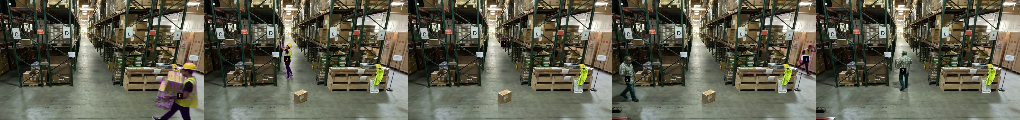

- How many different people appear in this video? Answer with a number.
- Does every person in this video wear a hard hat? Answer yes or no.
- Is a cardboard box left lying on the floor at some point in this video? Answer yes or no.
- One person picks a cardboard box up off the floor. Is that person wearing a high-visibility vest? Answer yes or no.
- There are signs with single letters on the shelf posts. Which letters are shown? Answer with the letters only.
- What colour is the hard hat worn by the first worker? One word.


Questions correct out of 6, for each fps (rows) and vision budget (columns):


max_vision_tokens,256,1024,4096
fps,,,
0.25,2,2,2
1.00,3,3,2
4.00,2,3,2


Total generation seconds for the six questions:


max_vision_tokens,256,1024,4096
fps,,,
0.25,0.25,0.27,0.73
1.00,0.25,0.33,0.66
4.00,0.45,0.65,1.16


In [31]:
display(frame_strip(WAREHOUSE_VIDEO, n=6, height=120))
for item in WAREHOUSE_QUESTIONS:
    print("-", item["q"])
WAREHOUSE = [dict(video=WAREHOUSE_VIDEO, **item) for item in WAREHOUSE_QUESTIONS]

# every combination of three frame rates and three vision budgets
grid = []
for fps in (0.25, 1, 4):
    for budget in (256, 1024, 4096):
        summary, _ = evaluate(WAREHOUSE, fps=fps, max_vision_tokens=budget)
        grid.append({"fps": fps, "max_vision_tokens": budget, **summary})
grid_df = pd.DataFrame(grid)
print("Questions correct out of 6, for each fps (rows) and vision budget (columns):")
display(grid_df.pivot(index="fps", columns="max_vision_tokens", values="correct"))
print("Total generation seconds for the six questions:")
display(grid_df.pivot(index="fps", columns="max_vision_tokens", values="total_gen_s"))

On the test clips, the right `fps` and budget took the score from zero to perfect. Check whether that happens here. If the score stays low across the whole grid, the limit is the model and the question, and no setting in that grid fixes it. A 2 billion parameter model watching 46 seconds of cluttered footage in one pass has real limits.

The per-question view shows where it fails, direct and with reasoning:

In [32]:
for reasoning in (False, True):
    summary, table = evaluate(WAREHOUSE, fps=2, max_vision_tokens=4096, reasoning=reasoning)
    print(f"\nreasoning = {reasoning}: {summary['correct']}/{summary['questions']} correct, {summary['total_gen_s']} s")
    display(table[["question", "truth", "answer", "correct", "gen_s"]])


reasoning = False: 3/6 correct, 0.67 s


,question,truth,answer,correct,gen_s
0,How many different people appear in this video? Answer with a,2,3,False,0.11
1,Does every person in this video wear a hard hat? Answer yes or,no,No,True,0.11
2,Is a cardboard box left lying on the floor at some point in th,yes,Yes.,True,0.12
3,One person picks a cardboard box up off the floor. Is that per,no,Yes,False,0.11
4,There are signs with single letters on the shelf posts. Which,(function),CD,False,0.11
5,What colour is the hard hat worn by the first worker? One word,yellow,Yellow,True,0.11



reasoning = True: 2/6 correct, 15.86 s


,question,truth,answer,correct,gen_s
0,How many different people appear in this video? Answer with a,2,3,False,1.87
1,Does every person in this video wear a hard hat? Answer yes or,no,no,True,1.46
2,Is a cardboard box left lying on the floor at some point in th,yes,(no answer: cut off while thinking),False,6.83
3,One person picks a cardboard box up off the floor. Is that per,no,yes,False,1.90
4,There are signs with single letters on the shelf posts. Which,(function),"C, D, E, A, B",False,2.96
5,What colour is the hard hat worn by the first worker? One word,yellow,yellow,True,0.84


Compare the two tables. Reasoning multiplies the time. Check whether it raised the score, and whether any reasoning run was cut off before it answered. On perception questions like these it often changes nothing, because the model is not short of thinking: it is short of seeing.

Two other things to try before giving up on a question.

**Ask the way the model was trained to answer.** NVIDIA's own safety prompt for this clip is an open question with reasoning on. The same fact that the yes or no questions above probe (does everyone wear safety equipment?) is asked here in NVIDIA's words.

**Narrow the question to one moment.** `clip=` sends only the seconds where the second person appears, so the whole budget goes to them.

In [33]:
r = ask("were all the workers working safety equipment", video=WAREHOUSE_VIDEO, fps=2, max_vision_tokens=4096, reasoning=True, max_new_tokens=1200)
print("NVIDIA's safety prompt, with reasoning. Final answer:\n")
print(final_answer(r["text"]) or "(cut off while thinking)")
print(f"\noutput_tokens={r['output_tokens']}  gen_s={r['gen_s']}  hit_limit={r['hit_limit']}")

print("\nOne person at a time, using clip=(start, end):")
rows = []
for who, clip, hat_truth, vest_truth in (("first worker", (0, 12), "yes", "yes"), ("second person", (26, 45), "no", "no")):
    hat = ask("Is the person in this video wearing a hard hat? Answer yes or no.", video=WAREHOUSE_VIDEO, clip=clip, fps=2, max_vision_tokens=4096, max_new_tokens=8)["text"]
    vest = ask("Is the person in this video wearing a high-visibility vest? Answer yes or no.", video=WAREHOUSE_VIDEO, clip=clip, fps=2, max_vision_tokens=4096, max_new_tokens=8)["text"]
    rows.append({"who": who, "clip_seconds": clip, "hard hat (truth)": hat_truth, "hard hat (model)": hat,
                 "vest (truth)": vest_truth, "vest (model)": vest})
pd.DataFrame(rows)

NVIDIA's safety prompt, with reasoning. Final answer:

The answer is **no**. Only the first worker (in the yellow vest and purple pants) is explicitly shown wearing safety equipment (a yellow vest, which is common in warehouses for visibility). The second worker (gray shirt and khakis) is not shown as wearing any safety gear. Safety vests are often worn in warehouses, but the video does not confirm this for the second worker.

output_tokens=225  gen_s=2.05  hit_limit=False

One person at a time, using clip=(start, end):


,who,clip_seconds,hard hat (truth),hard hat (model),vest (truth),vest (model)
0,first worker,"(0, 12)",yes,Yes,yes,Yes
1,second person,"(26, 45)",no,No,no,Yes


Look at the vest answer for the second person. A high-visibility vest hangs on a post beside the pallet for the whole clip, in the same frames as a person who is not wearing one. A wrong "yes" there is the kind of error that only shows up on real footage, and it is why a test set built from your own camera is worth more than any published benchmark.

**What this part is for:** settings matter most when the model *can* do the task and the input is starving it. When the score does not move with the settings, change the question, narrow the clip, add reasoning, or use a larger model (Cosmos Reason 2 also comes in 8B and 32B).

## Part 14. Task gallery: NVIDIA's prompts on NVIDIA's footage

Cosmos Reason 2 was trained for specific physical AI tasks, and each has a prompt form that works best. These are the prompts from NVIDIA's Cosmos Cookbook prompt guide, run on the same media the guide uses. Reasoning is on where the guide turns it on.

Robot: next action
PROMPT: What can be the next immediate action?   [+ reasoning]


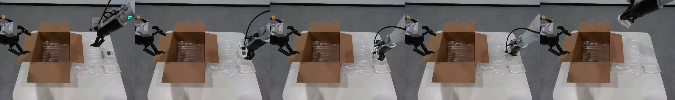

place the plastic bag into the cardboard box


Robot: goal verification
PROMPT: Has the robot successfully completed the intended packaging subtask? Explain why not.   [+ reasoning]


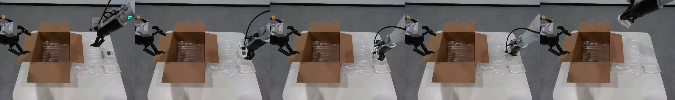

No, the robot has not successfully completed the intended packaging subtask. While Robot Arm 2 moves the small white object toward the cardboard box, the video does not show the object being placed inside the box or the air column wrap being utilized to cushion or secure it. Packaging typically requires both placing items into the box and applying protective materials (like the air column wrap), neither of which are explicitly demonstrated in the actions. The object remains in transit, and the box is empty, indicating incomplete execution of the task.


Driving: next action
PROMPT: What's the next immediate action for the Ego vehicle?   [+ reasoning]


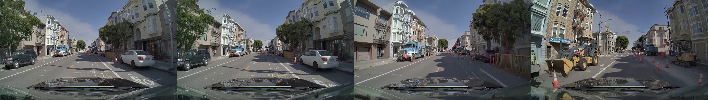

Stop at the STOP sign ahead


Video critic (is this generated clip physically plausible?)
PROMPT: Approve or reject this generated video for inclusion in a dataset for physical world model ai training. It must perfectly adhere to physics, object permanence, and have no anomalies. Any issue or concern causes rejection.   [+ reasoning]


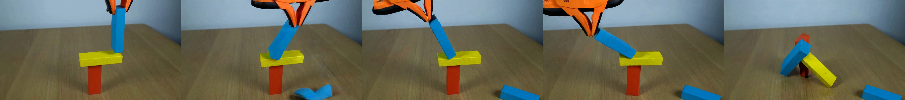

reject


Security
PROMPT: Is the person allowed to pick up the packages?   [+ reasoning]


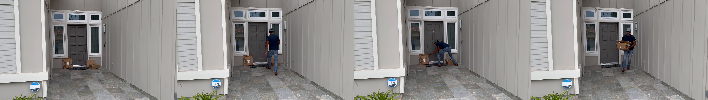

The person is allowed to pick up the packages based on the information provided. The video does not indicate any illegal activity, harassment, or violations of property rights. Packages delivered legally (e.g., via mail or courier) are typically accepted by homeowners unless prohibited by local ordinances, which are not shown here. The man complies with standard delivery protocols (knocking, opening the door, accepting packages), suggesting lawful behavior. Exceptions would require explicit evidence of trespassing, theft, or illegal delivery, none of which are evident in the scene.


Timestamped events (JSON)
PROMPT: Describe the notable events in the provided video. Provide the result in json format with 'mm:ss.ff' format for time depiction for each event. Use keywords 'start', 'end' and 'caption' in the json output.


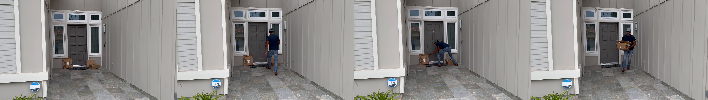

```json
[
  {
    "start": "00:00.100",
    "end": "00:03.200",
    "caption": "A man wearing a navy blue t-shirt, blue jeans, brown shoes, and a gray cap walks toward the front door of a house, pausing briefly as he approaches."
  },
  {
    "start": "00:03.200",
    "end": "00:09.500",
    "caption": "The man bends down and picks up two cardboard boxes placed near the doorstep, one of which he opens to reveal its contents."
  },
  {
    "start": "00:09.500",
    "end": "00:12.100",
    "caption": "Standing upright, the man carries the opened box away from the doorstep, walking confidently toward the camera while holding the box securely in his arms."
  }
]
```


,task,reasoning,frames,input_tokens,output_tokens,gen_s,hit_limit
0,Robot: next action,True,26,612,187,1.61,False
1,Robot: goal verification,True,26,619,320,2.71,False
2,Driving: next action,True,58,2212,208,1.90,False
3,Video critic (is this generated clip physically plausible?),True,23,2019,235,2.08,False
4,Security,True,48,1980,409,3.53,False
5,Timestamped events (JSON),False,48,1990,212,1.87,False


In [34]:
GALLERY = [
    ("Robot: next action", dict(video=PACKING_VIDEO), "What can be the next immediate action?", True),
    ("Robot: goal verification", dict(video=PACKING_VIDEO), "Has the robot successfully completed the intended packaging subtask? Explain why not.", True),
    ("Driving: next action", dict(video=DRIVING_VIDEO, max_vision_tokens=4096), "What's the next immediate action for the Ego vehicle?", True),
    ("Video critic (is this generated clip physically plausible?)", dict(video=GENERATED_VIDEO, max_vision_tokens=4096),
     "Approve or reject this generated video for inclusion in a dataset for physical world model ai training. It must perfectly adhere to physics, "
     "object permanence, and have no anomalies. Any issue or concern causes rejection.", True),
    ("Security", dict(video=DOORSTEP_VIDEO, max_vision_tokens=4096), "Is the person allowed to pick up the packages?", True),
    ("Timestamped events (JSON)", dict(video=DOORSTEP_VIDEO, max_vision_tokens=4096),
     "Describe the notable events in the provided video. Provide the result in json format with 'mm:ss.ff' format for time depiction for each event. "
     "Use keywords 'start', 'end' and 'caption' in the json output.", False),
]
gallery_rows = []
for title, media, prompt, reasoning in GALLERY:
    r = ask(prompt, reasoning=reasoning, max_new_tokens=1000, **media)
    print("=" * 100, f"\n{title}\nPROMPT: {prompt}" + ("   [+ reasoning]" if reasoning else ""))
    display(frame_strip(media["video"], n=5, height=100))
    print(final_answer(r["text"]) or "(no final answer: cut off while thinking)")
    gallery_rows.append({"task": title, "reasoning": reasoning, "frames": r["frames"], "input_tokens": r["input_tokens"],
                         "output_tokens": r["output_tokens"], "gen_s": r["gen_s"], "hit_limit": r["hit_limit"]})
pd.DataFrame(gallery_rows)

Check each answer against its frames. In the driving clip a worker holds up a STOP sign in the construction zone. In the generated clip a second blue block appears from nowhere, which is the kind of flaw the critic prompt exists to catch. The security question has no fact to check: it asks for a judgement, and the model's reasoning shows what it assumed. Treat judgement answers as a starting point for a person, never as a ruling.

### 14.1 Bounding boxes (2D grounding)

The prompt is `Locate the bounding box of {object}. Return a json.` The box comes back as `[x1, y1, x2, y2]` on a 0 to 1000 grid, whatever the image size, so multiply by `width / 1000` and `height / 1000` to get pixels.

```json
[
    {"bbox_2d": [462, 632, 567, 815], "label": "blue tape"}
]
``` 



```json
[
  {"bbox_2d": [322, 252, 622, 562], "label": "basket"}
]
``` 



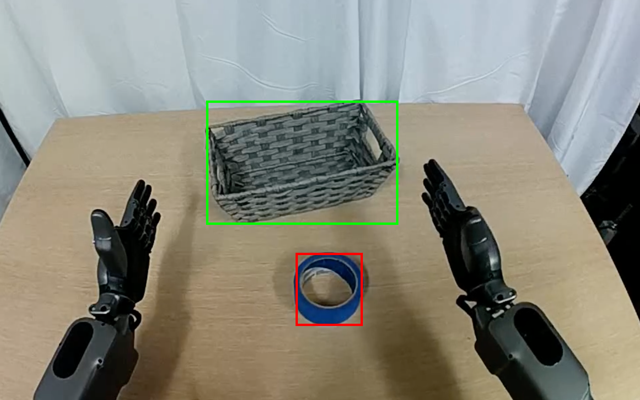

```json
[
  {"bbox_2d": [242, 454, 611, 992], "label": "pallet of water bottles"}
]
``` 



```json
[
  {"bbox_2d": [635, 329, 741, 564], "label": "forklift driver"}
]
``` 



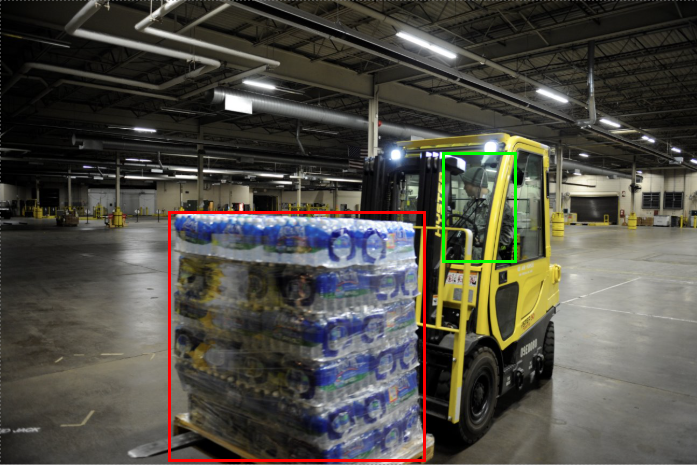

In [35]:
def draw_boxes(image_path, objects, colours=("red", "lime", "cyan", "yellow")):
    picture = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(picture)
    W, H = picture.size
    for obj, colour in zip(objects, colours):
        r = ask(f"Locate the bounding box of {obj}. Return a json.", image=image_path, max_new_tokens=128)
        print(r["text"], "\n")
        try:
            for item in parse_json(r["text"]):
                x1, y1, x2, y2 = item["bbox_2d"]
                draw.rectangle([x1 * W / 1000, y1 * H / 1000, x2 * W / 1000, y2 * H / 1000], outline=colour, width=max(3, W // 250))
        except Exception as e:
            print(f"Could not parse a box for {obj}: {e}")
    return picture

display(draw_boxes(ROBOT_IMAGE, ["the blue tape", "the basket"]).resize((640, 400)))
display(draw_boxes(FORKLIFT_IMAGE, ["the pallet of water bottles", "the forklift driver"]))

Name the object by what is visible. Asking this image for "the load on the forklift", an abstract description, returned junk text that ran to the token limit when this notebook was tested. "The pallet of water bottles" returned a clean box. The `try` block above is there because a grounding call can fail that way.

### 14.2 A robot trajectory (action chain of thought)

The model can also return points: a path for a gripper to follow, on the same 0 to 1000 grid. This is NVIDIA's "Action CoT" prompt on the robot image.

```json
[
  {"point_2d": [710, 556], "label": "gripper trajectory"},
  {"point_2d": [517, 682], "label": "gripper trajectory"},
  {"point_2d": [507, 658], "label": "gripper trajectory"},
  {"point_2d": [507, 457], "label": "gripper trajectory"},
  {"point_2d": [507, 457], "label": "gripper trajectory"}
]
```

Yellow dot: start. The path should reach the tape, then end over the basket.


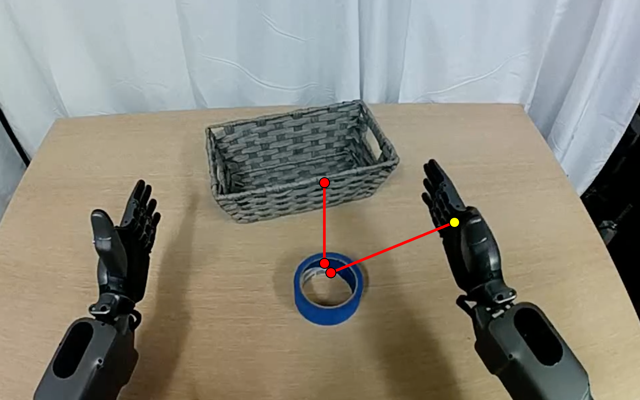

In [36]:
TRAJECTORY = ('You are given the task "Move the tape into the basket". Specify the 2D trajectory your end effector should follow in pixel space. '
              'Return the trajectory coordinates in JSON format like this: {"point_2d": [x, y], "label": "gripper trajectory"}.')
r = ask(TRAJECTORY, image=ROBOT_IMAGE, reasoning=True, max_new_tokens=1000)
print(final_answer(r["text"]) or "(no final answer: cut off while thinking)")

picture = Image.open(ROBOT_IMAGE).convert("RGB")
draw = ImageDraw.Draw(picture)
W, H = picture.size
try:
    points = [(p["point_2d"][0] * W / 1000, p["point_2d"][1] * H / 1000) for p in parse_json(final_answer(r["text"]))]
    draw.line(points, fill="red", width=8)
    for i, (x, y) in enumerate(points):
        draw.ellipse([x - 16, y - 16, x + 16, y + 16], fill="yellow" if i == 0 else "red", outline="black", width=3)
    print("\nYellow dot: start. The path should reach the tape, then end over the basket.")
except Exception as e:
    print("Could not parse the trajectory:", e)
display(picture.resize((640, 400)))

Check `hit_limit` on JSON calls in particular. A cut-off JSON answer does not parse.

## Part 15. Several images, and follow-up questions

### 15.1 More than one image in a call

`ask()` accepts a list of images. Each is encoded separately and they appear in the prompt in order, so the model can compare them. `max_vision_tokens` applies per image. The test: two copies of the label image, with one character changed on one box in the second.

In [37]:
changed_codes = list(CODES); changed_codes[4] = "HD-5297"        # BOX 5: last digit 1 -> 7
CHANGED_IMAGE = make_label_image("labels_changed.png", changed_codes)

r = ask("These two images show the same six boxes at two different times. The code on one box label is different in the second image. "
        "Which box number changed, and what are the old and new codes?",
        image=[LABEL_IMAGE, CHANGED_IMAGE], max_vision_tokens=1024, max_new_tokens=60)
print("Truth: BOX 5 changed from HD-5291 to HD-5297\n")
show(r)

Truth: BOX 5 changed from HD-5291 to HD-5297

The box number that changed is BOX 5. The old code was HD-5291, and the new code is HD-5297.

input_tokens=2063  vision_tokens=2000  output_tokens=34  prep_s=0.05  gen_s=0.4  first_token_s=0.12  tokens_per_s=85.6  peak_gpu_gb=4.7  hit_limit=False


`input_tokens` is about double a single-image call. Two images cost two budgets.

### 15.2 Follow-up questions (multi-turn chat)

A conversation is a growing list of messages. To ask a follow-up, append the model's answer as an `assistant` message and your next question as a new `user` message, then send the whole list again. The image is sent once, in the first turn, and its tokens are re-read on every turn.

In [38]:
class Chat:
    def __init__(self, image, max_vision_tokens=1024):
        self.image = (Image.open(image) if isinstance(image, str) else image).convert("RGB")
        self.size = {"shortest_edge": 16 * PIXELS_PER_TOKEN, "longest_edge": max_vision_tokens * PIXELS_PER_TOKEN}
        self.messages = [{"role": "system", "content": [{"type": "text", "text": SYSTEM_PROMPT}]}]

    def say(self, text, max_new_tokens=120):
        content = [{"type": "text", "text": text}]
        if len(self.messages) == 1:                       # first turn: the image goes before the text
            content.insert(0, {"type": "image"})
        self.messages.append({"role": "user", "content": content})
        prompt_text = processor.apply_chat_template(self.messages, tokenize=False, add_generation_prompt=True)
        inputs = processor(text=[prompt_text], images=[self.image], return_tensors="pt", size=self.size).to(model.device)
        with torch.inference_mode():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        answer = processor.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
        self.messages.append({"role": "assistant", "content": [{"type": "text", "text": answer}]})
        print(f"YOU:   {text}\nMODEL: {answer}\n       (input tokens this turn: {inputs['input_ids'].shape[1]})\n")

chat = Chat(ROBOT_IMAGE)
chat.say("What objects are on the table? Answer in one sentence.")
chat.say("Which of those is closest to the bottom of the image?")
chat.say("What colour is it?")

YOU:   What objects are on the table? Answer in one sentence.
MODEL: There is a gray woven basket, a blue tape roll, and two black prosthetic hands.
       (input tokens this turn: 1033)



YOU:   Which of those is closest to the bottom of the image?
MODEL: The blue tape roll is closest to the bottom of the image.
       (input tokens this turn: 1074)

YOU:   What colour is it?
MODEL: It is blue.
       (input tokens this turn: 1102)



The follow-ups say "those" and "it", and the model resolves them from the earlier turns. The input token count rises each turn, because the whole history is sent again. Long conversations fill the context window (Part 7), so drop old turns when they stop mattering.

## Part 16. Speed and memory: batching and 4-bit loading

### 16.1 Batching: several questions in one pass

A GPU can process several prompts side by side. Instead of eight calls, build eight prompts, pad them to the same length and run `generate` once. Padding must go on the left, so every prompt ends right where the answer begins.

In [39]:
BATCH_QUESTIONS = ["What colour is the roll of tape? One word.", "How many robot hands are visible? Answer with a number.",
                   "Is the basket empty? Answer yes or no.", "What is the table made of? One word.",
                   "Is there a person in the image? Answer yes or no.", "What shape is the basket? One word.",
                   "What colour is the basket? One word.", "What colour is the curtain behind the table? One word."]

def ask_batch(prompts, image, max_vision_tokens=1024, max_new_tokens=12):
    picture = (Image.open(image) if isinstance(image, str) else image).convert("RGB")
    texts = [processor.apply_chat_template(
        [{"role": "system", "content": [{"type": "text", "text": SYSTEM_PROMPT}]},
         {"role": "user", "content": [{"type": "image"}, {"type": "text", "text": p}]}],
        tokenize=False, add_generation_prompt=True) for p in prompts]
    processor.tokenizer.padding_side = "left"
    size = {"shortest_edge": 16 * PIXELS_PER_TOKEN, "longest_edge": max_vision_tokens * PIXELS_PER_TOKEN}
    inputs = processor(text=texts, images=[picture] * len(prompts), return_tensors="pt", padding=True, size=size).to(model.device)
    with torch.inference_mode():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return [t.strip() for t in processor.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)]

torch.cuda.synchronize(); t0 = time.perf_counter()
one_by_one = [ask(q, image=ROBOT_IMAGE, max_new_tokens=12)["text"] for q in BATCH_QUESTIONS]
torch.cuda.synchronize(); t1 = time.perf_counter()
torch.cuda.reset_peak_memory_stats()
batched = ask_batch(BATCH_QUESTIONS, ROBOT_IMAGE)
torch.cuda.synchronize(); t2 = time.perf_counter()

display(pd.DataFrame({"question": BATCH_QUESTIONS, "one by one": one_by_one, "batched": batched}))
print(f"one by one: {t1 - t0:.2f} s    batched: {t2 - t1:.2f} s    speed-up: {(t1 - t0) / (t2 - t1):.1f}x    "
      f"peak GPU memory while batched: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

,question,one by one,batched
0,What colour is the roll of tape? One word.,Blue,Blue
1,How many robot hands are visible? Answer with a number.,2,2
2,Is the basket empty? Answer yes or no.,"Yes, the basket is empty.","Yes, the basket is empty."
3,What is the table made of? One word.,wood,wood
4,Is there a person in the image? Answer yes or no.,No,No
5,What shape is the basket? One word.,rectangle,rectangle
6,What colour is the basket? One word.,gray,gray
7,What colour is the curtain behind the table? One word.,White,White


one by one: 1.20 s    batched: 0.87 s    speed-up: 1.4x    peak GPU memory while batched: 6.0 GB


What to read here: the answers should match between the two columns, the batched run should finish sooner, and its peak memory is higher, because eight copies of the image are in memory at once. How much time you save depends on the GPU: a batch helps most when single calls leave the GPU partly idle. Batch size is limited by memory, so lower the vision budget if a large batch runs out.

This helper sends the same image eight times. For different images per question, pass a list of images in the same order as the prompts.

### 16.2 4-bit loading: a third of the memory

The weights loaded in Part 1 are 16-bit. `bitsandbytes` can store them in 4 bits, which cuts the memory the model holds to roughly a third. That lets the model share a small GPU with something else. The cost is that the weights are approximations and each step does extra work to unpack them. The cell loads a 4-bit copy next to the 16-bit one and compares memory, speed and accuracy on the same tests.

In [40]:
from transformers import BitsAndBytesConfig

before = torch.cuda.memory_allocated()
model_4bit = transformers.Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID, device_map="auto", attn_implementation="sdpa",
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16),
)
weights_4bit_gb = (torch.cuda.memory_allocated() - before) / 1e9
_ = ask("Hi", image=ROBOT_IMAGE, max_new_tokens=4, use_model=model_4bit)     # warm-up

rows = []
for name, m, weights_gb in (("16-bit (float16)", model, before / 1e9), ("4-bit (bitsandbytes nf4)", model_4bit, weights_4bit_gb)):
    codes = {b: codes_read(ask(READ_CODES, image=LABEL_IMAGE, max_vision_tokens=b, max_new_tokens=80, use_model=m)["text"]) for b in (128, 256, 1024)}
    digits = ask(LIST_DIGITS, video=DIGIT_VIDEO, max_new_tokens=40, use_model=m)
    speed = ask("Describe this image in detail.", image=ROBOT_IMAGE, max_new_tokens=200, use_model=m)
    rows.append({"weights": name, "weights_gb": round(weights_gb, 1), "tokens_per_s": speed["tokens_per_s"],
                 "codes read at 128 / 256 / 1024 tokens (of 6)": f"{codes[128]} / {codes[256]} / {codes[1024]}",
                 "digit video correct": digits_said(digits["text"]) == DIGITS})
display(pd.DataFrame(rows))

del m, model_4bit                                   # free the 4-bit copy
import gc; gc.collect(); torch.cuda.empty_cache()

,weights,weights_gb,tokens_per_s,codes read at 128 / 256 / 1024 tokens (of 6),digit video correct
0,16-bit (float16),4.3,115.9,3 / 6 / 6,True
1,4-bit (bitsandbytes nf4),1.7,86.7,3 / 4 / 6,True


What to read here:

- `weights_gb` drops to about a third.
- `tokens_per_s` drops too. 4-bit loading saves memory and costs speed.
- Accuracy on easy tasks holds. Look at the middle code-reading number, the vision budget where the 16-bit model only just reads every code. That is where an approximate model slips first.

**Rule:** use 4-bit loading when memory is the constraint. If the model already fits, 16-bit is both faster and more accurate. For production speed, NVIDIA's repository documents other quantized formats served through vLLM.

## Part 17. Streaming, and the same parameters on a server

### 17.1 Streaming

Generation takes the same total time either way, but with a streamer you see tokens as they are written. For anything a person waits on, the time to the first word (Part 8) matters more than the total.

In [41]:
from transformers import TextStreamer
streamer = TextStreamer(processor.tokenizer, skip_prompt=True, skip_special_tokens=True)
r = ask("Describe this image in three sentences.", image=ROBOT_IMAGE, max_new_tokens=150, streamer=streamer)

An 

empty 

gray 

woven 

basket 

sits 

... (20 outputs left out)

side 

of 

the 

basket.


### 17.2 The same parameters on a vLLM server

This notebook calls the model in-process with `transformers`, which is the simplest way to learn. For deployment NVIDIA recommends serving it with vLLM, which exposes an OpenAI-compatible API. The ideas are identical and the names change.

Nothing in this section runs in the notebook, because vLLM installs its own PyTorch and belongs in a separate environment. Every command and request below was run against a live server with **vLLM 0.33.0** on an RTX 5090 workstation (not on Colab). vLLM changes quickly, so check the flags against your version.

**Start the server.** This is NVIDIA's command plus one flag that current vLLM needs before it accepts per-request image settings:

```bash
vllm serve nvidia/Cosmos-Reason2-2B \
  --max-model-len 8192 \
  --media-io-kwargs '{"video": {"num_frames": -1}}' \
  --reasoning-parser qwen3 \
  --trust-request-mm-kwargs \
  --port 8000
```

**Call it** with the OpenAI client:

```python
import base64
from openai import OpenAI

client = OpenAI(base_url="http://localhost:8000/v1", api_key="EMPTY")

def data_url(path, mime):
    return f"data:{mime};base64," + base64.b64encode(open(path, "rb").read()).decode()

response = client.chat.completions.create(
    model="nvidia/Cosmos-Reason2-2B",
    messages=[
        {"role": "system", "content": [{"type": "text", "text": "You are a helpful assistant."}]},
        {"role": "user", "content": [
            {"type": "video_url", "video_url": {"url": data_url("digits.mp4", "video/mp4")}},   # media first
            {"type": "text", "text": "List every digit that appears, in order."},
        ]},
    ],
    max_tokens=40,                 # max_new_tokens
    temperature=0,                 # greedy
    extra_body={
        "media_io_kwargs": {"video": {"fps": 4}},                                               # fps for this request
        "mm_processor_kwargs": {"size": {"shortest_edge": 16 * 1024, "longest_edge": 1024 * 1024}},   # vision token budget
        "chat_template_kwargs": {"enable_thinking": False},                                      # see the reasoning note below
    },
)
print(response.choices[0].message.content, response.usage)
```

| In this notebook | On a vLLM server | Observed in testing |
|---|---|---|
| context window (Part 7) | `--max-model-len` at server start | A request with a longer input is refused: `Input length (11007) exceeds model's maximum context length (8192)`. A `max_tokens` larger than the room left is accepted. |
| `max_new_tokens` | `max_tokens` in the request | |
| `fps` | `extra_body={"media_io_kwargs": {"video": {"fps": 4}}}` | Needs `--media-io-kwargs '{"video": {"num_frames": -1}}'` at start. On the digit clip, 1 fps returned three digits and 4 fps returned all six. Putting `fps` in `mm_processor_kwargs` had no effect. |
| `max_vision_tokens` | `extra_body={"mm_processor_kwargs": {"size": {...}}}` in pixels (tokens x 1024) | Refused unless the server is started with `--trust-request-mm-kwargs`. |
| `reasoning=True` | same prompt add-on | With `--reasoning-parser qwen3`, the thinking arrives in `message.reasoning` and the answer in `message.content`. |
| reasoning off | `extra_body={"chat_template_kwargs": {"enable_thinking": False}}` | Without this, the parser put the whole plain answer in `message.reasoning` and left `message.content` empty. If your answers come back empty, this is why. |
| `temperature`, `top_p`, `seed` | same names in the request | |
| `top_k`, `repetition_penalty` | inside `extra_body` | |
| (not available here) | `presence_penalty` in the request | NVIDIA's default for normal calls is 1.5. |

One difference to expect: the server's default image and video resizing is not the same as this notebook's, so the same file can cost a different number of tokens there. Read `response.usage.prompt_tokens` and set the size explicitly.

## Part 18. Tune it on your own data

Everything above used someone else's media. The method transfers directly:

1. Collect a few images or clips from **your** camera.
2. Write 10 to 20 questions whose answers you have checked by eye. Include the cases you care most about getting right.
3. Sweep one setting at a time with `sweep()` and pick the cheapest value where accuracy has levelled off.

The cell below is a template. It runs on the warehouse clip so it works as it stands. Replace `MY_QUESTIONS` with your own.

,max_vision_tokens,correct,questions,accuracy,total_gen_s,avg_output_tokens,peak_gpu_gb
0,64,4,8,0.50,0.35,3.4,4.30
1,256,5,8,0.62,0.37,3.4,4.33
2,1024,7,8,0.88,0.50,3.5,4.48
3,4096,8,8,1.00,0.85,3.5,4.74


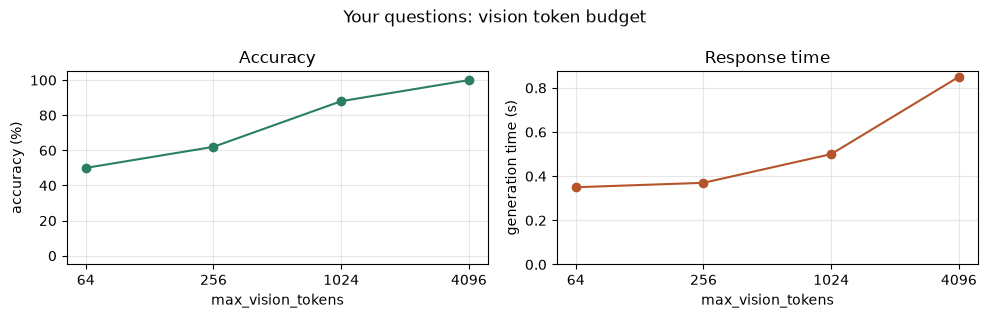

,question,truth,answer,correct,gen_s
0,Is the person in this video wearing a hard hat? Answer yes or,yes,Yes,True,0.04
1,What is the person carrying? One word.,box,package,False,0.05
2,Is the person in this video wearing a hard hat? Answer yes or,no,No,True,0.04
3,Does the person pick something up from the floor? Answer yes o,yes,Yes.,True,0.05
4,What colour is the forklift? One word.,yellow,yellow,True,0.04
5,Is the forklift carrying a load? Answer yes or no.,yes,Yes,True,0.04
6,Is the basket empty? Answer yes or no.,yes,"Yes, the basket is empty.",True,0.12
7,Read the code on the white label of BOX 2. Answer with the cod,bt-9153,BT-9153,True,0.11


In [42]:
MY_QUESTIONS = [
    # media                                 question                                                  checked answer
    dict(video=WAREHOUSE_VIDEO, clip=(0, 12),  q="Is the person in this video wearing a hard hat? Answer yes or no.", truth="yes"),
    dict(video=WAREHOUSE_VIDEO, clip=(0, 12),  q="What is the person carrying? One word.",                             truth="box"),
    dict(video=WAREHOUSE_VIDEO, clip=(26, 45), q="Is the person in this video wearing a hard hat? Answer yes or no.", truth="no"),
    dict(video=WAREHOUSE_VIDEO, clip=(26, 45), q="Does the person pick something up from the floor? Answer yes or no.", truth="yes"),
    dict(image=FORKLIFT_IMAGE,                 q="What colour is the forklift? One word.",                             truth="yellow"),
    dict(image=FORKLIFT_IMAGE,                 q="Is the forklift carrying a load? Answer yes or no.",                 truth="yes"),
    dict(image=ROBOT_IMAGE,                    q="Is the basket empty? Answer yes or no.",                             truth="yes"),
    dict(image=LABEL_IMAGE,                    q="Read the code on the white label of BOX 2. Answer with the code only.", truth="bt-9153"),
]

budget_sweep = sweep(MY_QUESTIONS, "max_vision_tokens", [64, 256, 1024, 4096], fps=2)
display(budget_sweep)
two_panel(budget_sweep, "max_vision_tokens", "Your questions: vision token budget")

summary, table = evaluate(MY_QUESTIONS, fps=2, max_vision_tokens=1024)
display(table[["question", "truth", "answer", "correct", "gen_s"]])

Read the sweep from the top: find the first row where `accuracy` stops improving, and use that value. Everything above it is time and memory with nothing in return. Then read the per-question table and look at what is still wrong. Those are the cases to fix with a crop, a clip, reasoning or a larger model, in that order of cost.

Other sweeps to try with the same call:

```python
sweep(MY_QUESTIONS, "fps", [0.5, 1, 2, 4], max_vision_tokens=1024)        # video questions only
sweep(MY_QUESTIONS, "reasoning", [False, True], max_vision_tokens=1024)
sweep(MY_QUESTIONS, "media_first", [True, False])
```

To use your own files, upload them with the folder icon in Colab's left bar, then:

```python
show(ask("What is happening here?", image="my_photo.jpg"))
show(ask("Caption the video in detail.", video="my_clip.mp4", fps=4, max_vision_tokens=2048))
show(ask("What happens here?", video="my_clip.mp4", clip=(10, 20)))       # only seconds 10 to 20
```

## Part 19. Cheat sheet

| Parameter | What it controls | Raise it when | Cost of raising it | Start with |
|---|---|---|---|---|
| `max_new_tokens` | longest possible answer | answers are cut off (`hit_limit`) | none, unless the model rambles | 256 for answers, 4096 with reasoning |
| `max_vision_tokens` | image or clip detail | small text or small objects are misread | time to first token, memory | 1024 for images |
| `fps` | how often the model looks at a video | short events are missed | more frames, less detail per frame | 4 (the training value) |
| `clip` | which seconds of a video are sent | (narrow it for long video or one moment) | more calls | whole video for short clips |
| `reasoning` | think before answering | the question needs several steps | many times the output tokens and time | off |
| `do_sample`, `temperature` | randomness | you want varied wording | repeatability, and accuracy at high values | greedy for anything you measure |
| `top_p`, `top_k` | which tokens sampling may pick | (lower them to make sampling safer) | less variety | model defaults: 0.8 and 20 |
| `repetition_penalty` | reuse of tokens | the output loops | can distort exact strings such as codes | 1.0 |
| `seed` | the random draw | never: fix it | none | any fixed number |
| context window | input plus output tokens | you send long video | memory | count first with `build_inputs()` |

**When a call is slow**

| What you see | Cause | Fix |
|---|---|---|
| `first_token_s` is most of `gen_s` | too many input tokens | lower `max_vision_tokens` or `fps`, crop, or clip |
| `first_token_s` is small, `gen_s` is large | long output | ask for a shorter answer format, turn reasoning off |
| many short calls | per-call overhead | batch them (Part 16) |

**When an answer is wrong**

| What you see | Likely cause | Fix |
|---|---|---|
| wrong small details, stated confidently | vision budget too low | raise it, or crop (Part 5) |
| a short event is missing | `fps` too low | raise `fps` (Part 6) |
| events lost or repeated in a long video | too much for one call | split into clips, mind the boundaries (Part 6.3) |
| wrong on a multi-step question | no room to work it out | reasoning on (Part 9) |
| describes something that is not there | leading question | ask if it exists first, add an escape clause (Part 12) |
| different answer each run | sampling is on, or the model is guessing | greedy decoding. If sampled answers scatter, treat the answer as unreliable (Part 12) |
| still wrong at every setting | beyond the model | change the question, or use the 8B or 32B model (Part 13) |

### Troubleshooting

| Symptom | Cause and fix |
|---|---|
| `401` or `GatedRepoError` on download | Accept the license on the model page and check the `HF_TOKEN` secret has notebook access. |
| `CUDA out of memory` | Lower `max_vision_tokens` or `fps`, or shorten the clip. Then **Runtime > Restart session** to clear the GPU. |
| Answer stops mid-sentence, or reasoning has no final answer | `hit_limit` is `True`. Raise `max_new_tokens`. |
| JSON does not parse | The answer was cut off (`hit_limit`), or reasoning text came before it. Parse `final_answer(text)`. |
| Video loading errors about `torchcodec` or `torchvision` | The library's built-in video loader is in use. Read frames with OpenCV as `read_video()` does here. |
| A media file failed to download | The part that uses it fails and the others still run. Re-run the cell in 1.5. |
| Empty `content` from a vLLM server | The reasoning parser moved the answer to `message.reasoning`. See Part 17. |

### Sources

- Model card: https://huggingface.co/nvidia/Cosmos-Reason2-2B
- Code, sample script and prompt templates: https://github.com/nvidia-cosmos/cosmos-reason2
- Cosmos Cookbook prompt guide (task prompts, recommended sampling values, sample footage): https://nvidia-cosmos.github.io/cosmos-cookbook/getting_started/prompt_guide/reason_guide.html
- Qwen3-VL, the base architecture: https://github.com/QwenLM/Qwen3-VL
- vLLM: https://docs.vllm.ai

### About the author

Obinna Edeh runs EmbodiedEdge, a Physical AI lab. He designs and builds Physical AI and edge AI systems, and proves them on real robots and hardware. He runs Cosmos Reason 2 on a Jetson AGX Thor.

- Urban Edge Vision Analytics: https://github.com/obiedeh/urban-edge-vision-analytics
- Physical AI Safety Observability: https://github.com/obiedeh/physical-ai-safety-observability
- GitHub: https://github.com/obiedeh
- Lab: https://embodiededge.ai

This is independent work. It is not affiliated with or endorsed by NVIDIA. Tested on a Google Colab A100 runtime and on an RTX 5090 workstation.